# SCADA Data Analysis: Reading, Plotting and Filtering with Clustering

Wind turbine SCADA systems record the 10-minute **average, standard deviation, minimum and maximum** of many channels (wind speed, power, rotor speed, pitch angle, temperatures, ...). SCADA data is the starting point of almost every data-driven wind energy application, but it is **never ready to use**: it contains missing and/or duplicated records and POTENTIAL outliers as well as different operational regimes such as start-ups and shut-downs, stand-still periods, curtailment.

In this exercise we use one year of data from four turbine wind farm (T01, T06, T07, T11) and go through the typical first steps of a SCADA analysis:

1. **Read** the raw file and run basic data-quality checks
2. **Plot** the data to see what needs attention
3. **Filter manually** with physical rules (thresholds)
4. **Filter automatically** with three clustering algorithms, **GMM**, **DBSCAN** and **HDBSCAN**, and compare them with the rule-based result
5. **Combine** the methods and write the feature table used in the next exercises (`Data_TimeSeries.csv`)


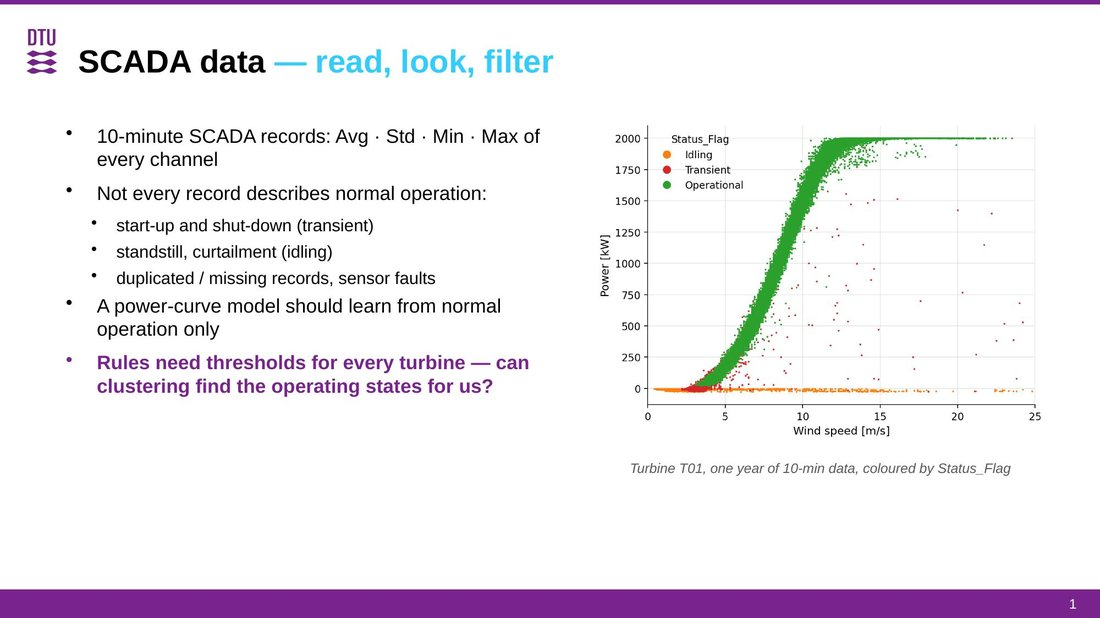

## 0 · Setup

Let us begin by importing the libraries

In [1]:
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

---
# 1 · Reading the data

## 1.1 Read the raw file

A `.csv` file is not always *comma*-separated. Before reading it with pandas, have a quick look at the first line of the file to identify the **delimiter**.

In [2]:
file = r"Data/data_exercise_SCADA_analysis_filtering_clustering.csv"

# Peek at the beginning of the first line (the header) to identify the delimiter
with open(file) as f:
    print(f.readline()[:150])

Turbine_ID;Timestamp;Gen_RPM_Max;Gen_RPM_Min;Gen_RPM_Avg;Gen_RPM_Std;Gen_Bear_Temp_Avg;Gen_Phase1_Temp_Avg;Gen_Phase2_Temp_Avg;Gen_Phase3_Temp_Avg;Hyd


In [3]:
InputData = pd.read_csv(file, delimiter=';')
print('Shape:', InputData.shape, '  (rows, columns)')
InputData.head()

Shape: (209236, 84)   (rows, columns)


,Turbine_ID,Timestamp,Gen_RPM_Max,Gen_RPM_Min,Gen_RPM_Avg,Gen_RPM_Std,Gen_Bear_Temp_Avg,Gen_Phase1_Temp_Avg,Gen_Phase2_Temp_Avg,Gen_Phase3_Temp_Avg,...,Grd_Prod_PsbleInd_Max,Grd_Prod_PsbleInd_Min,Grd_Prod_PsbleInd_Std,Grd_Prod_PsbleCap_Avg,Grd_Prod_PsbleCap_Max,Grd_Prod_PsbleCap_Min,Grd_Prod_PsbleCap_Std,Gen_Bear2_Temp_Avg,Nac_Direction_Avg,Status_Flag
0,T01,2017-01-13 03:40:00+00:00,1262.1,205.9,852.9,474.8,35.0,54,55,55,...,0.0,-498.3,110.8,53.1,498.3,0.0,110.8,33,342.6,1
1,T07,2017-01-13 03:50:00+00:00,1359.1,236.2,769.7,465.0,38.0,60,60,59,...,0.0,-604.1,75.6,21.4,604.1,0.0,75.6,39,333.6,1
2,T07,2017-01-13 04:40:00+00:00,233.1,158.5,203.5,22.7,35.0,46,47,47,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33,326.7,2
3,T07,2017-01-13 05:00:00+00:00,1250.7,113.7,351.2,388.3,33.0,42,42,42,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31,310.1,2
4,T01,2017-01-13 05:00:00+00:00,206.4,143.0,158.0,14.5,30.0,36,36,36,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,27,311.0,2


> 💡 If you end up with **one single, very wide column**, the delimiter is wrong.

## 1.2 Check and correct the timestamp format

The `Timestamp` column was read as plain text (strings). Converting it to a proper **datetime** type allows us to slice by time (e.g. `.loc['2017-03']`), to resample and to sort correctly.

In [4]:
print('Before:', InputData['Timestamp'].dtype, '|', InputData['Timestamp'].iloc[0])

InputData['Timestamp'] = pd.to_datetime(InputData['Timestamp'])

print('After :', InputData['Timestamp'].dtype, '|', InputData['Timestamp'].iloc[0])

Before: object | 2017-01-13 03:40:00+00:00
After : datetime64[ns, UTC] | 2017-01-13 03:40:00+00:00


## 1.3 Data-quality checks

SCADA data is never perfect. Before doing anything else, run three quick checks:

1. **Missing values** (NaN)
2. **Duplicated records**: the same turbine at the same time stamp twice
3. **Gaps** in the 10-minute sequence (we will look at these in a later section)

In [5]:
# 1. Missing values
missing = InputData.isna().sum()
print('Columns with missing values:')
print(missing[missing > 0].to_string())

# 2. Duplicated records: the same turbine at the same time stamp
dup_mask = InputData.duplicated(subset=['Turbine_ID', 'Timestamp'], keep=False)
print('\nRecords involved in duplicated (Turbine_ID, Timestamp) pairs:', dup_mask.sum())

Columns with missing values:
Gen_Bear_Temp_Avg      4
Grd_Prod_CosPhi_Avg    4

Records involved in duplicated (Turbine_ID, Timestamp) pairs: 48


There are duplicates. Before we simply delete them, let us find out **why** they exist: when do they occur, and are the two copies identical?

In [6]:
dups = InputData[dup_mask].sort_values(['Turbine_ID', 'Timestamp'])
print('Date(s)   :', dups['Timestamp'].dt.date.unique())
print('Time(s)   :', sorted(dups['Timestamp'].dt.strftime('%H:%M').unique()))
print('Extra copies per turbine:')
print(InputData[InputData.duplicated(subset=['Turbine_ID', 'Timestamp'])]['Turbine_ID'].value_counts().sort_index().to_string())

dups[['Turbine_ID', 'Timestamp', 'Amb_WindSpeed_Avg', 'Grd_Prod_Pwr_Avg', 'Status_Flag']].head(6)

Date(s)   : [datetime.date(2017, 10, 29)]
Time(s)   : ['02:00', '02:10', '02:20', '02:30', '02:40', '02:50']
Extra copies per turbine:
Turbine_ID
T01    6
T06    6
T07    6
T11    6


,Turbine_ID,Timestamp,Amb_WindSpeed_Avg,Grd_Prod_Pwr_Avg,Status_Flag
32053,T01,2017-10-29 02:00:00+00:00,10.2,1609.7,0
50148,T01,2017-10-29 02:00:00+00:00,10.6,1719.1,0
31060,T01,2017-10-29 02:10:00+00:00,9.4,1399.4,0
49607,T01,2017-10-29 02:10:00+00:00,10.7,1774.7,0
31063,T01,2017-10-29 02:20:00+00:00,8.7,1101.3,0
31064,T01,2017-10-29 02:20:00+00:00,11.5,1891.3,0


🔎 **What is going on?** All duplicates sit on one single day, 29 Oct 2017, between 02:00 and 02:50: 6 records × 4 turbines = 24 extra rows, i.e. exactly **one repeated hour**. The two copies carry *different* measurements (compare wind speed and power above), so they are not copy-paste errors.

This is the typical fingerprint of the **clock change at the end of daylight saving time**: local clock time was most likely stored with a `+00:00` (UTC) label, so one hour appears twice. For this exercise we keep the first occurrence. In a real project you would rather shift the second copy by one hour, or ask for the data in true UTC.

## 1.4 Clean up and index the data

We remove the duplicated records and use **(Turbine_ID, Timestamp)** as a *multi-index*. This lets us pick one turbine at a time with `.xs('T01', level='Turbine_ID')`, and `sort_index()` also fixes the unsorted order of the raw file.

In [7]:
InputData = InputData.drop_duplicates(subset=['Turbine_ID', 'Timestamp'], keep='first')
InputData = InputData.set_index(['Turbine_ID', 'Timestamp']).sort_index()
print('Shape after removing duplicates:', InputData.shape)
InputData.head(3)

Shape after removing duplicates: (209212, 82)


Gen_RPM_Max  Gen_RPM_Min  Gen_RPM_Avg  \
Turbine_ID Timestamp                                                          
T01        2017-01-01 00:00:00+00:00       1460.9       1239.2       1313.7   
           2017-01-01 00:10:00+00:00       1410.6       1229.4       1271.3   
           2017-01-01 00:20:00+00:00       1444.1       1226.7       1270.4   

                                      Gen_RPM_Std  Gen_Bear_Temp_Avg  \
Turbine_ID Timestamp                                                   
T01        2017-01-01 00:00:00+00:00         47.9               36.0   
           2017-01-01 00:10:00+00:00         27.6               36.0   
           2017-01-01 00:20:00+00:00         30.8               36.0   

                                      Gen_Phase1_Temp_Avg  \
Turbine_ID Timestamp                                        
T01        2017-01-01 00:00:00+00:00                   57   
           2017-01-01 00:10:00+00:00                   57   
           2017-01-01 00:20:00+00:00                   56   

                                      Gen_Phase2_Temp_Avg  \
Turbine_ID Timestamp                                        
T01        2017-01-01 00:00:00+00:00                   57   
           2017-01-01 00:10:00+00:00                   57   
           2017-01-01 00:20:00+00:00                   56   

                                      Gen_Phase3_Temp_Avg  Hyd_Oil_Temp_Avg  \
Turbine_ID Timestamp                                                          
T01        2017-01-01 00:00:00+00:00                   57                26   
           2017-01-01 00:10:00+00:00                   57                26   
           2017-01-01 00:20:00+00:00                   56                26   

                                      Gear_Oil_Temp_Avg  ...  \
Turbine_ID Timestamp                                     ...   
T01        2017-01-01 00:00:00+00:00                 47  ...   
           2017-01-01 00:10:00+00:00                 47  ...   
           2017-01-01 00:20:00+00:00                 46  ...   

                                      Grd_Prod_PsbleInd_Max  \
Turbine_ID Timestamp                                          
T01        2017-01-01 00:00:00+00:00                 -621.9   
           2017-01-01 00:10:00+00:00                 -477.2   
           2017-01-01 00:20:00+00:00                 -291.4   

                                      Grd_Prod_PsbleInd_Min  \
Turbine_ID Timestamp                                          
T01        2017-01-01 00:00:00+00:00                -1000.0   
           2017-01-01 00:10:00+00:00                -1000.0   
           2017-01-01 00:20:00+00:00                -1000.0   

                                      Grd_Prod_PsbleInd_Std  \
Turbine_ID Timestamp                                          
T01        2017-01-01 00:00:00+00:00                   67.1   
           2017-01-01 00:10:00+00:00                  120.9   
           2017-01-01 00:20:00+00:00                  149.3   

                                      Grd_Prod_PsbleCap_Avg  \
Turbine_ID Timestamp                                          
T01        2017-01-01 00:00:00+00:00                  978.4   
           2017-01-01 00:10:00+00:00                  900.7   
           2017-01-01 00:20:00+00:00                  865.2   

                                      Grd_Prod_PsbleCap_Max  \
Turbine_ID Timestamp                                          
T01        2017-01-01 00:00:00+00:00                 1000.0   
           2017-01-01 00:10:00+00:00                 1000.0   
           2017-01-01 00:20:00+00:00                 1000.0   

                                      Grd_Prod_PsbleCap_Min  \
Turbine_ID Timestamp                                          
T01        2017-01-01 00:00:00+00:00                  621.9   
           2017-01-01 00:10:00+00:00                  477.2   
           2017-01-01 00:20:00+00:00                  291.4   

                                      Grd_Prod_PsbleCap_

## 1.5 Overview per turbine

How many valid records do we have per turbine, and how complete is the one-year record? A full year of 10-minute data has 365 × 144 = 52,560 records.

,valid records,completeness [%],mean wind speed [m/s],mean power [kW]
Turbine_ID,,,,
T01,52238,99.4,6.1,540.8
T06,52340,99.6,6.1,568.8
T07,52288,99.5,6.3,567.5
T11,52346,99.6,6.0,540.5


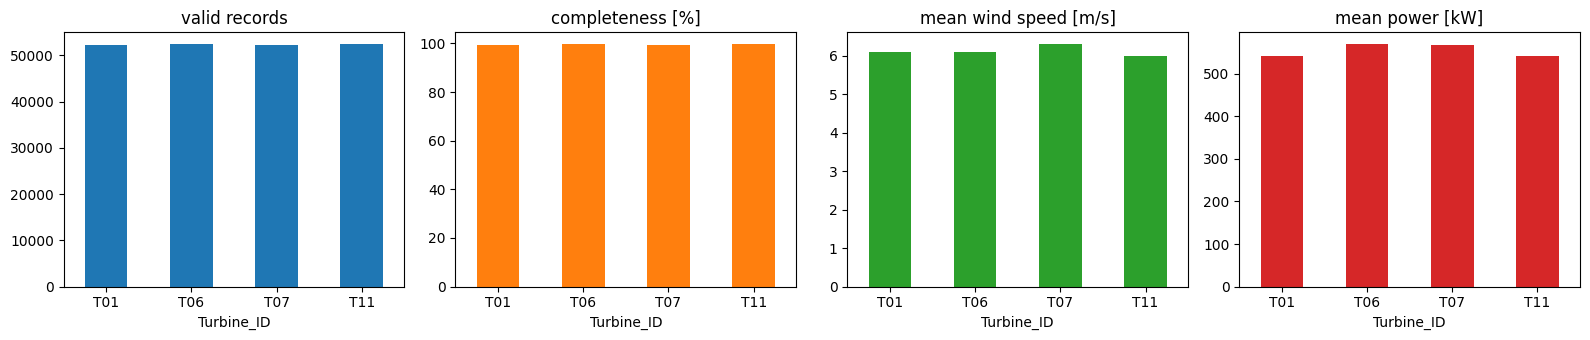

In [8]:
expected = 365 * 144          # number of 10-minute records in one year
by_turbine = InputData.groupby(level='Turbine_ID')

summary = pd.DataFrame({
    'valid records': by_turbine.size(),
    'completeness [%]': 100 * by_turbine.size() / expected,
    'mean wind speed [m/s]': by_turbine['Amb_WindSpeed_Avg'].mean(),
    'mean power [kW]': by_turbine['Grd_Prod_Pwr_Avg'].mean(),
}).round(1)
display(summary)

summary.plot(kind='bar', subplots=True, layout=(1, 4), figsize=(16, 3.5), legend=False, rot=0)
plt.tight_layout(); plt.show()

All turbines are ~99.5% complete (the remaining gaps are short), and the four turbines have similar mean wind speed and power across the year, as expected within a small wind farm with minimal wake effects.

---
# 2 · Plotting: what needs attention?

Before filtering anything, **look at the data**. We make four views of turbine T01:

1. a time series
2. the power curve of every turbine
3. a scatter matrix of several channels
4. the Min/Max statistics against wind speed

## 2.1 Time series

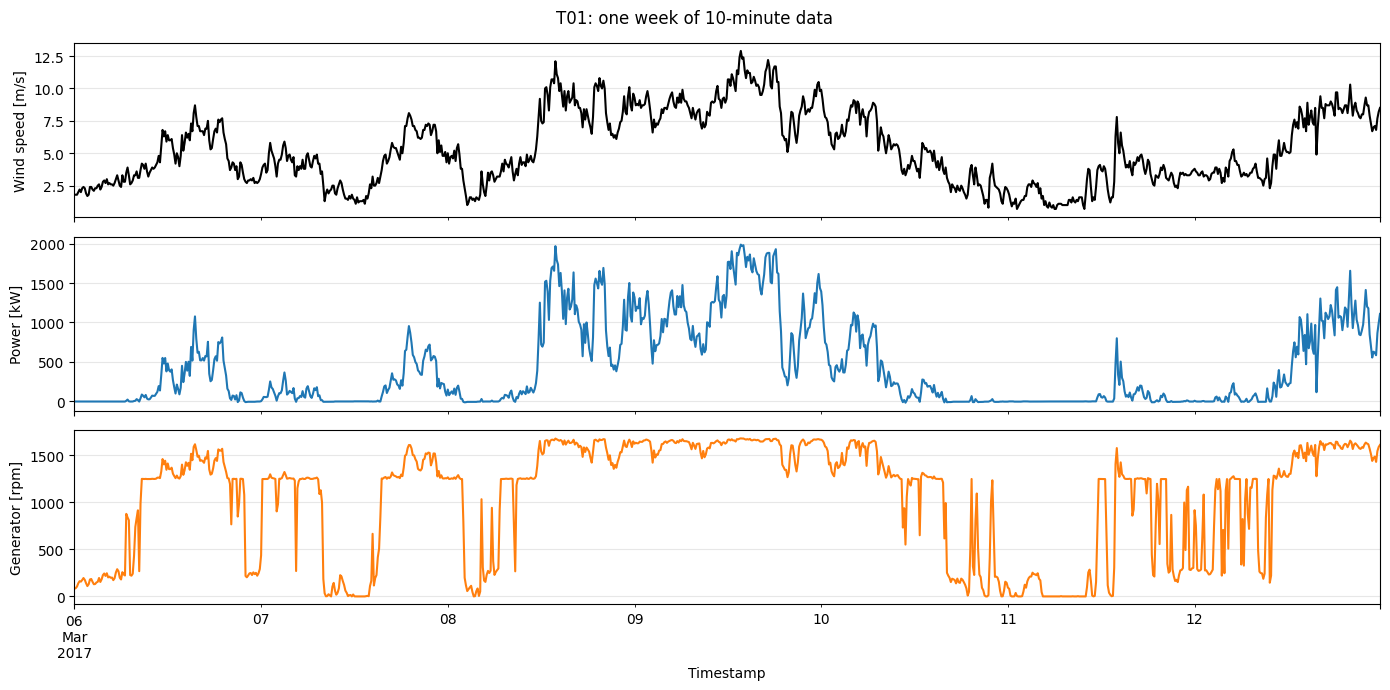

In [9]:
turbine = 'T01'
T = InputData.xs(turbine, level='Turbine_ID')        # one turbine, indexed by Timestamp

week = T.loc['2017-03-06':'2017-03-12']
fig, ax = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
week['Amb_WindSpeed_Avg'].plot(ax=ax[0], color='k');   ax[0].set_ylabel('Wind speed [m/s]')
week['Grd_Prod_Pwr_Avg'].plot(ax=ax[1], color='C0');   ax[1].set_ylabel('Power [kW]')
week['Gen_RPM_Avg'].plot(ax=ax[2], color='C1');        ax[2].set_ylabel('Generator [rpm]')
for a in ax: a.grid(alpha=0.3)
fig.suptitle(f'{turbine}: one week of 10-minute data'); plt.tight_layout(); plt.show()

The turbine follows the wind, but look at the generator speed (bottom): in light winds around the **cut-in** speed (~3-5 m/s) it keeps jumping between ~0 and ~1250 rpm: the turbine starts and stops again and again, and for long periods it stands still. SCADA data does **not** only describe normal operation.

## 2.2 The operational power curve of every turbine

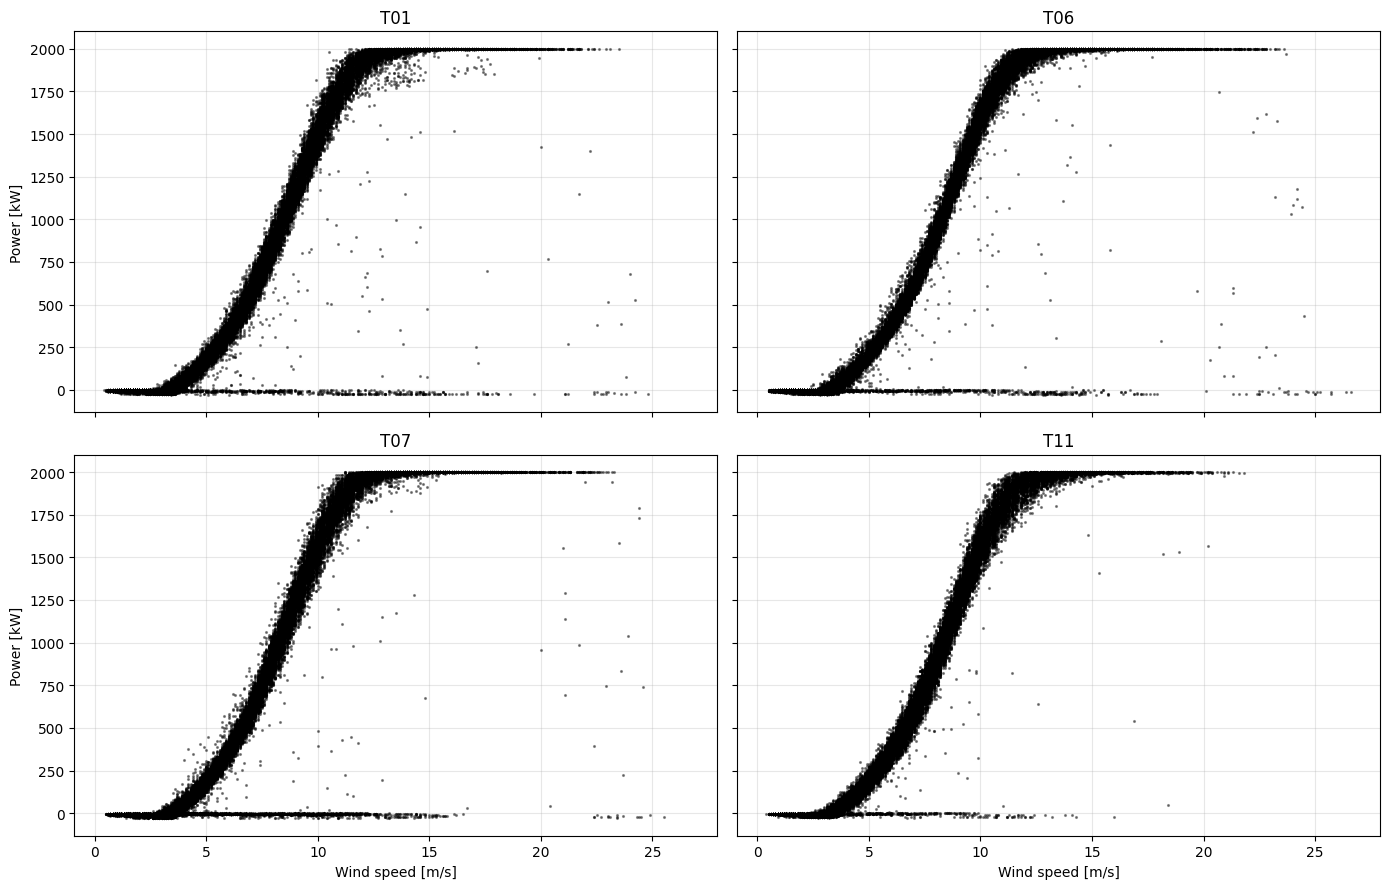

In [10]:
turbines = InputData.index.get_level_values('Turbine_ID').unique()

fig, ax = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
for a, tid in zip(ax.ravel(), turbines):
    d = InputData.xs(tid, level='Turbine_ID')
    a.plot(d['Amb_WindSpeed_Avg'], d['Grd_Prod_Pwr_Avg'], '.', ms=2.5, color='k', alpha=0.4)
    a.set_title(tid); a.grid(alpha=0.3)
for a in ax[1, :]: a.set_xlabel('Wind speed [m/s]')
for a in ax[:, 0]: a.set_ylabel('Power [kW]')
plt.tight_layout(); plt.show()

What do we see in the power curves?

- the typical **S-shaped power curve**: cut-in at ~3 m/s, rated power of 2 MW from ~12 m/s
- a **horizontal line at ~0 kW for all wind speeds**: the turbine stands still although the wind blows (downtime, curtailment, faults)
- points **between** the two populations (start-up and shut-down) and a few **stray outliers**

All four turbines show the same picture. For the rest of the exercise we work with **T01**.

## 2.3 Scatter matrix of several channels

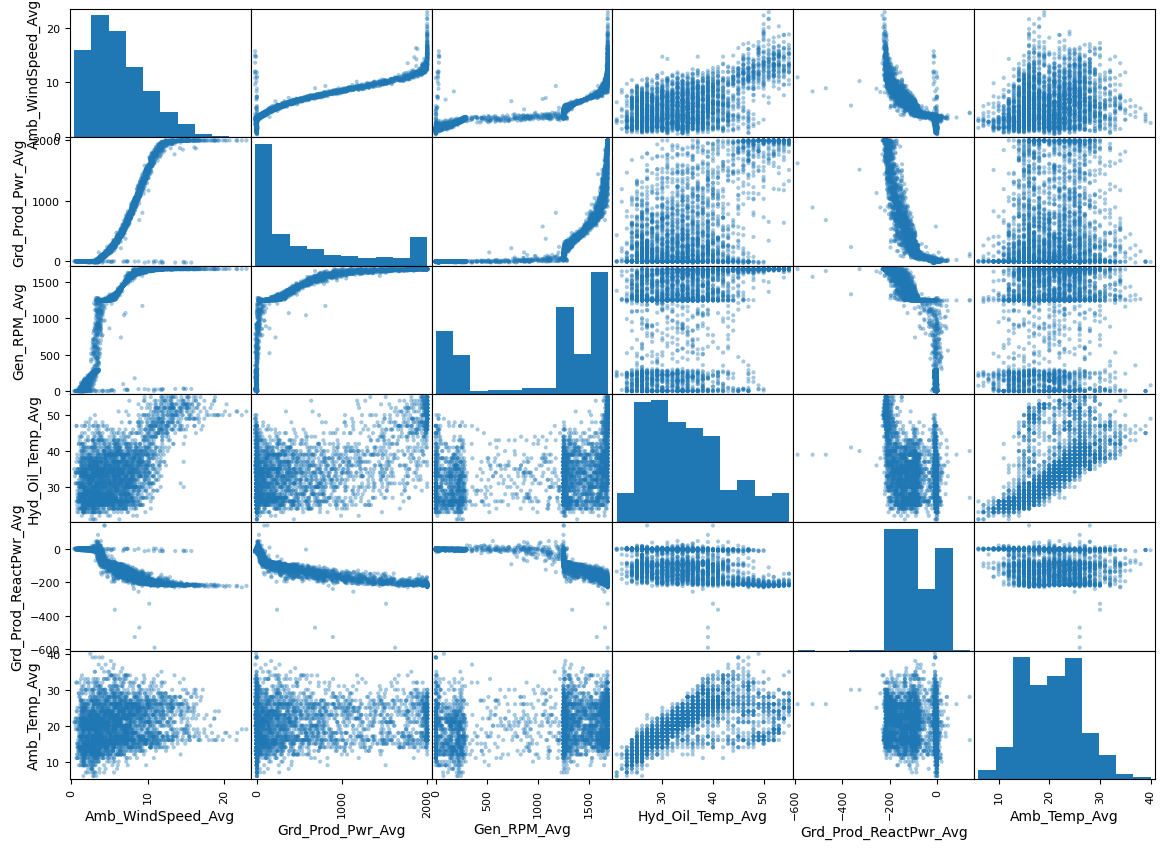

In [11]:
chan = ['Amb_WindSpeed_Avg', 'Grd_Prod_Pwr_Avg', 'Gen_RPM_Avg',
        'Hyd_Oil_Temp_Avg', 'Grd_Prod_ReactPwr_Avg', 'Amb_Temp_Avg']

# 52,000 points per panel would be slow to draw: a random sample of 3,000 records is enough to see the structure
pd.plotting.scatter_matrix(T[chan].sample(3000, random_state=0), figsize=(14, 10), diagonal='hist', alpha=0.4)
plt.show()

Things to notice: the S-shaped relation between wind speed and power; the generator speed has **two populations** (stopped/slow versus ~1250-1650 rpm); and the hydraulic oil temperature follows the ambient temperature rather than the power. Not every channel is useful for finding the operating state.

## 2.4 Min and Max statistics against wind speed

Each record is a 10-minute window. The **Min** and **Max** channels tell us what happened *inside* that window. Let us look at them against wind speed:

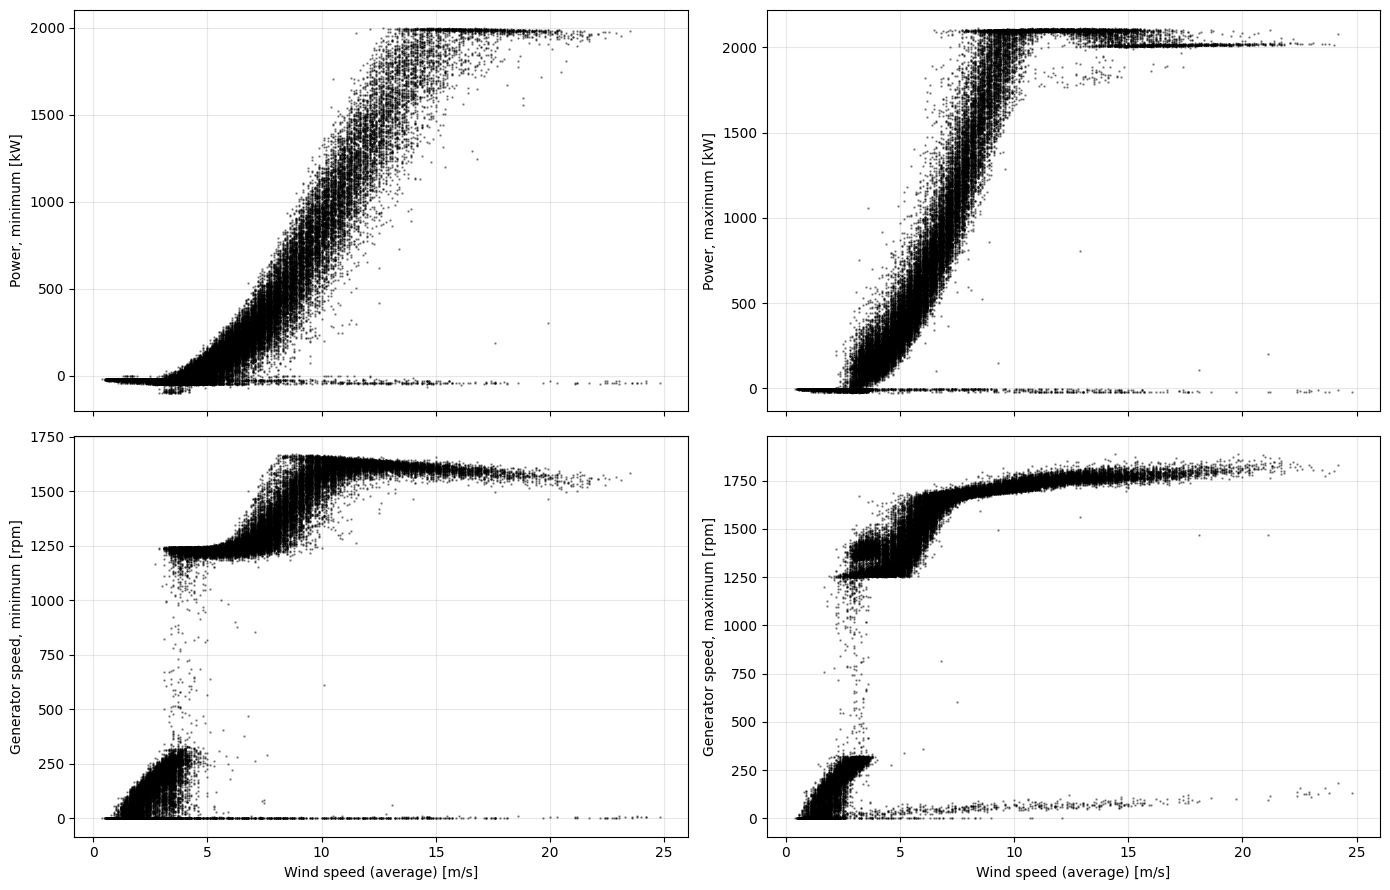

In [12]:
pairs = [('Grd_Prod_Pwr_Min', 'Power, minimum [kW]'), ('Grd_Prod_Pwr_Max', 'Power, maximum [kW]'),
         ('Gen_RPM_Min', 'Generator speed, minimum [rpm]'), ('Gen_RPM_Max', 'Generator speed, maximum [rpm]')]

fig, ax = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for a, (col, ylabel) in zip(ax.ravel(), pairs):
    a.plot(T['Amb_WindSpeed_Avg'], T[col], '.', ms=1.5, color='k', alpha=0.4)
    a.set_ylabel(ylabel); a.grid(alpha=0.3)
for a in ax[1, :]: a.set_xlabel('Wind speed (average) [m/s]')
plt.tight_layout(); plt.show()

Notice the **sharp boundaries** in the Min/Max plots: for example the generator speed (`Gen_RPM_Max`) jumps to ~1250 rpm when the turbine is producing, and the minimum power (`Grd_Prod_Pwr_Min`) separates records where power stayed positive from records where it dropped to zero. We will use these boundaries to define filtering rules.

---
# 3 · Manual (rule-based) filtering

A turbine is in **normal operation** when the generator runs at operating speed and keeps producing power during the **whole** 10 minutes. In terms of masks (boolean conditions):

| State | Condition |
|---|---|
| **Operational** | generator reached operating speed **and** power never dropped to ~zero |
| **Transient** | generator reached operating speed and some power was produced, but power dropped to ~zero within the window (start-up / shut-down) |
| **Idling** | everything else |

Use the plots of section 2.4 to choose the two thresholds.

In [13]:
T = InputData.xs('T01', level='Turbine_ID')           # work with one turbine

power_min_threshold = 1       # [kW]  minimum power at or below this = power dropped to ~zero
rpm_max_threshold   = 1250    # [rpm] maximum generator speed at or above this = generator at operating speed

MaxPowerMask = T['Grd_Prod_Pwr_Max'] >= 1                      # some power was produced
MinPowerMask = T['Grd_Prod_Pwr_Min'] <= power_min_threshold    # power dropped to ~zero at some point
MaxRPMMask   = T['Gen_RPM_Max'] >= rpm_max_threshold           # generator reached operating speed

OperationalMask = MaxRPMMask & ~MinPowerMask                   # at speed AND never stopped producing
TransientMask   = MaxPowerMask & MaxRPMMask & ~OperationalMask # ramping up / down within the 10 minutes
IdlingMask      = ~OperationalMask & ~TransientMask            # everything else

for name, m in [('Operational', OperationalMask), ('Transient', TransientMask), ('Idling', IdlingMask)]:
    print(f'{name:12s}: {m.sum():6d} records ({m.mean():.1%})')

Operational :  30786 records (58.9%)
Transient   :   7325 records (14.0%)
Idling      :  14127 records (27.0%)


The data set also comes with a `Status_Flag` column (**0 = operational, 1 = transient, 2 = idling**). How well do our rules agree with it?

In [14]:
T = InputData.xs('T01', level='Turbine_ID')
rule_state = np.select([OperationalMask, TransientMask], [0, 1], default=2)

print(f'Agreement of our rules with Status_Flag: {(rule_state == T["Status_Flag"].values).mean():.1%}\n')
pd.crosstab(rule_state, T['Status_Flag'].values, rownames=['our rules'], colnames=['Status_Flag'])

Agreement of our rules with Status_Flag: 100.0%



Status_Flag,0,1,2
our rules,,,
0,30786,0,0
1,0,7325,0
2,0,0,14127


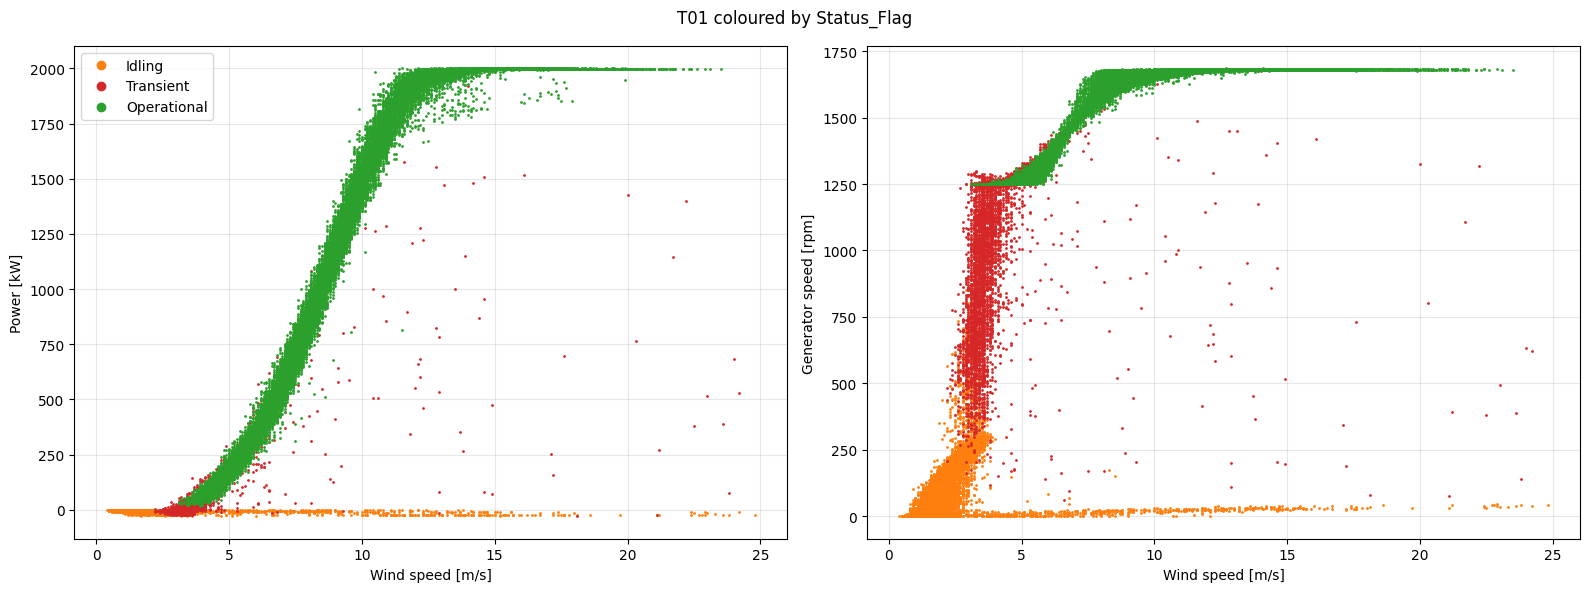

In [15]:
states = {0: ('Operational', 'C2'), 1: ('Transient', 'C3'), 2: ('Idling', 'C1')}

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for flag in (2, 1, 0):
    name, color = states[flag]
    m = T['Status_Flag'] == flag
    ax[0].plot(T.loc[m, 'Amb_WindSpeed_Avg'], T.loc[m, 'Grd_Prod_Pwr_Avg'], '.', ms=2, color=color, label=name)
    ax[1].plot(T.loc[m, 'Amb_WindSpeed_Avg'], T.loc[m, 'Gen_RPM_Avg'], '.', ms=2, color=color, label=name)
ax[0].set_ylabel('Power [kW]'); ax[1].set_ylabel('Generator speed [rpm]')
for a in ax: a.set_xlabel('Wind speed [m/s]'); a.grid(alpha=0.3)
ax[0].legend(markerscale=6)
fig.suptitle('T01 coloured by Status_Flag'); plt.tight_layout(); plt.show()

🔎 With thresholds of 1 kW and 1250 rpm the rules reproduce the `Status_Flag` **exactly**: the flag itself is the output of a rule-based classification. So we will use it as a **reference**, not as absolute truth.

Rules work well if you know the thresholds, but they have to be set **per turbine and site**, they need expert knowledge, and they say nothing about stray *outliers* inside the operational state.

> **Can an algorithm that does *not* know the thresholds rediscover these operating states from the data alone?**

That is the question for the rest of the exercise. We will only use the status flag to *check* the results, never to train anything.

---
# 4 · Feature table and scaling

## 4.1 Feature table

We describe every 10-minute record by **4 channels × 4 statistics = 16 features**: wind speed, power, generator speed and pitch angle, each as average (`Avg`), standard deviation (`Std`), minimum (`Min`) and maximum (`Max`).

The **Std / Min / Max features are crucial**: they tell us what happened *within* the 10 minutes. A record with an average power of 300 kW can be a steady state (min ≈ max ≈ 300 kW) or a start-up ramp (min = 0 kW, max = 600 kW).

In [16]:
ChannelList  = ['Amb_WindSpeed', 'Grd_Prod_Pwr', 'Gen_RPM', 'Blds_PitchAngle']
StatsList    = ['Avg', 'Std', 'Min', 'Max']
FeatureNames = [f'{ch}_{st}' for ch in ChannelList for st in StatsList]
print(len(FeatureNames), 'features:', FeatureNames)

FeatureList = InputData[FeatureNames]
FeatureList.head(3)

16 features: ['Amb_WindSpeed_Avg', 'Amb_WindSpeed_Std', 'Amb_WindSpeed_Min', 'Amb_WindSpeed_Max', 'Grd_Prod_Pwr_Avg', 'Grd_Prod_Pwr_Std', 'Grd_Prod_Pwr_Min', 'Grd_Prod_Pwr_Max', 'Gen_RPM_Avg', 'Gen_RPM_Std', 'Gen_RPM_Min', 'Gen_RPM_Max', 'Blds_PitchAngle_Avg', 'Blds_PitchAngle_Std', 'Blds_PitchAngle_Min', 'Blds_PitchAngle_Max']


Amb_WindSpeed_Avg  Amb_WindSpeed_Std  \
Turbine_ID Timestamp                                                         
T01        2017-01-01 00:00:00+00:00                5.6                1.1   
           2017-01-01 00:10:00+00:00                4.9                1.0   
           2017-01-01 00:20:00+00:00                4.9                1.0   

                                      Amb_WindSpeed_Min  Amb_WindSpeed_Max  \
Turbine_ID Timestamp                                                         
T01        2017-01-01 00:00:00+00:00                1.5               10.0   
           2017-01-01 00:10:00+00:00                1.5               18.5   
           2017-01-01 00:20:00+00:00                1.6               10.5   

                                      Grd_Prod_Pwr_Avg  Grd_Prod_Pwr_Std  \
Turbine_ID Timestamp                                                       
T01        2017-01-01 00:00:00+00:00             291.5              62.9   
           2017-01-01 00:10:00+00:00             207.5              55.0   
           2017-01-01 00:20:00+00:00             199.7              61.9   

                                      Grd_Prod_Pwr_Min  Grd_Prod_Pwr_Max  \
Turbine_ID Timestamp                                                       
T01        2017-01-01 00:00:00+00:00             129.6             428.7   
           2017-01-01 00:10:00+00:00              98.0             413.8   
           2017-01-01 00:20:00+00:00              60.6             387.7   

                                      Gen_RPM_Avg  Gen_RPM_Std  Gen_RPM_Min  \
Turbine_ID Timestamp                                                          
T01        2017-01-01 00:00:00+00:00       1313.7         47.9       1239.2   
           2017-01-01 00:10:00+00:00       1271.3         27.6       1229.4   
           2017-01-01 00:20:00+00:00       1270.4         30.8       1226.7   

                                      Gen_RPM_Max  Blds_PitchAngle_Avg  \
Turbine_ID Timestamp                                                     
T01        2017-01-01 00:00:00+00:00       1460.9                 -1.5   
           2017-01-01 00:10:00+00:00       1410.6                 -1.0   
           2017-01-01 00:20:00+00:00       1444.1                 -1.0   

                                      Blds_PitchAngle_Std  \
Turbine_ID Timestamp                                        
T01        2017-01-01 00:00:00+00:00                  0.4   
           2017-01-01 00:10:00+00:00                  0.4   
           2017-01-01 00:20:00+00:00                  0.5   

                                      Blds_PitchAngle_Min  Blds_PitchAngle_Max  
Turbine_ID Timestamp                                                            
T01        2017-01-01 00:00:00+00:00                 -2.2                 -0.2  
           2017-01-01 00:10:00+00:00                 -2.3                  0.5  
           2017-01-01 00:20:00+00:00                 -2.2                  0.1

## 4.2 One turbine and feature scaling

From now on we work with **T01**. The 16 features have very different units and ranges (power up to 2000 kW, wind speed ~0-25 m/s, pitch angle in degrees). Clustering algorithms are based on **distances** between records, so without scaling the large-valued features (power, rpm) would dominate the result.

We therefore **standardise** every feature to zero mean and unit variance.

In [17]:
from sklearn.preprocessing import StandardScaler

T01 = InputData.xs('T01', level='Turbine_ID')      # 1 turbine = one time series of ~52,000 records
X01 = T01[FeatureNames]

scaler = StandardScaler()
X01_sc = scaler.fit_transform(X01)

pd.DataFrame({'mean (raw)': X01.mean(), 'std (raw)': X01.std(),
              'mean (scaled)': X01_sc.mean(axis=0), 'std (scaled)': X01_sc.std(axis=0)},
             index=FeatureNames).round(2)

,mean (raw),std (raw),mean (scaled),std (scaled)
Amb_WindSpeed_Avg,6.09,3.71,-0.0,1.0
Amb_WindSpeed_Std,1.17,0.71,-0.0,1.0
Amb_WindSpeed_Min,1.71,1.25,0.0,1.0
Amb_WindSpeed_Max,12.61,7.27,0.0,1.0
Grd_Prod_Pwr_Avg,540.78,668.79,0.0,1.0
Grd_Prod_Pwr_Std,94.74,104.38,0.0,1.0
Grd_Prod_Pwr_Min,316.30,516.59,-0.0,1.0
Grd_Prod_Pwr_Max,760.03,796.37,0.0,1.0
Gen_RPM_Avg,1070.08,614.61,-0.0,1.0
Gen_RPM_Std,67.82,109.50,-0.0,1.0


## 4.3 Helper functions (given)

To keep the clustering sections short, we define three helper functions. You do not need to change them:

- `cluster_profile(labels)`: size and **median** of key channels for every cluster. This is how we *read* and *name* the clusters
- `plot_clusters(labels, title)`: power curve and generator-speed view coloured by cluster (noise = black crosses)
- `evaluate_filter(keep, name)`: compares a *normal operation* mask with the rule-based reference using
  - **precision**: of the records we keep, how many are rule-based *operational*?
  - **recall**: of the rule-based *operational* records, how many do we keep?

In [19]:
reference = (T01['Status_Flag'] == 0).values      # rule-based 'operational' state - used ONLY to check the results
results   = pd.DataFrame(index=T01.index)         # we collect the 'normal operation' mask of every method here
fit_time  = {}                                    # fit time of every method [s]

profile_cols = ['Amb_WindSpeed_Avg', 'Grd_Prod_Pwr_Avg', 'Grd_Prod_Pwr_Min',
                'Gen_RPM_Min', 'Gen_RPM_Max', 'Blds_PitchAngle_Avg']

def cluster_profile(labels):
    """Size and median of key channels for every cluster (label -1 = noise)."""
    labels = np.asarray(labels)
    prof = T01[profile_cols].groupby(labels).median().round(1)
    prof.insert(0, 'size', pd.Series(labels).value_counts().sort_index().reindex(prof.index).values)
    return prof

def plot_clusters(labels, title, max_clusters=8):
    """Power curve and generator speed against wind speed, coloured by cluster. Noise (-1) in black."""
    labels = np.asarray(labels)
    sizes = pd.Series(labels[labels >= 0]).value_counts()
    main = sizes.index[:max_clusters]
    fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
    for a, (y, ylab) in zip(ax, [('Grd_Prod_Pwr_Avg', 'Power [kW]'), ('Gen_RPM_Avg', 'Generator speed [rpm]')]):
        small = (labels >= 0) & ~np.isin(labels, main)
        if small.any():
            a.plot(T01['Amb_WindSpeed_Avg'][small], T01[y][small], '.', ms=2, color='lightgrey', label='other small clusters')
        for i, c in enumerate(main):
            m = labels == c
            a.plot(T01['Amb_WindSpeed_Avg'][m], T01[y][m], '.', ms=2, color=f'C{i}', label=f'cluster {c}  (n={m.sum()})')
        m = labels == -1
        if m.any():
            a.plot(T01['Amb_WindSpeed_Avg'][m], T01[y][m], 'x', ms=3, color='k', label=f'noise  (n={m.sum()})')
        a.set_xlabel('Wind speed [m/s]'); a.set_ylabel(ylab); a.grid(alpha=0.3)
    ax[0].legend(markerscale=5, fontsize=9, loc='upper left')
    fig.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

def evaluate_filter(keep, name):
    """Compare a 'normal operation' mask with the rule-based reference."""
    keep = np.asarray(keep)
    tp = (keep & reference).sum()
    precision, recall = tp / keep.sum(), tp / reference.sum()
    return {'method': name, 'kept [%]': round(100 * keep.mean(), 1),
            'precision': round(precision, 3), 'recall': round(recall, 3),
            'F1': round(2 * precision * recall / (precision + recall), 3)}

print(f'{reference.mean():.1%} of the T01 records are rule-based "operational": keeping everything would give precision = {reference.mean():.3f}')

58.9% of the T01 records are rule-based "operational": keeping everything would give precision = 0.589


---
# 5 · Filtering with clustering

We will filter T01 with three clustering algorithms. They differ in *how* they define a cluster, but the recipe is always the same, only step 2 changes:

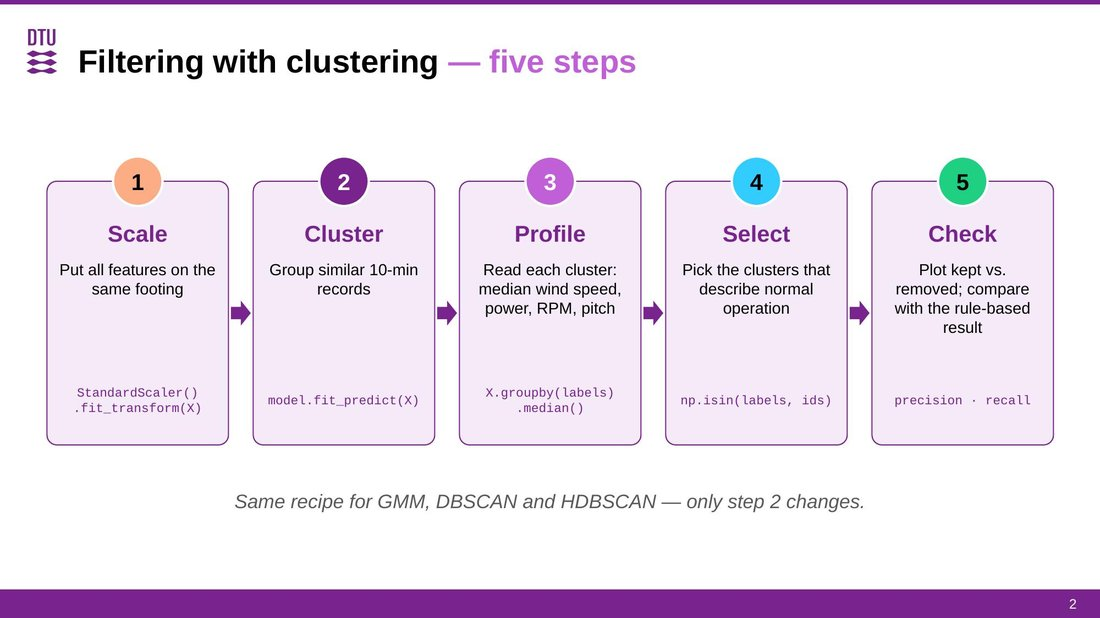

---
## 5.1 Gaussian Mixture Model (GMM)

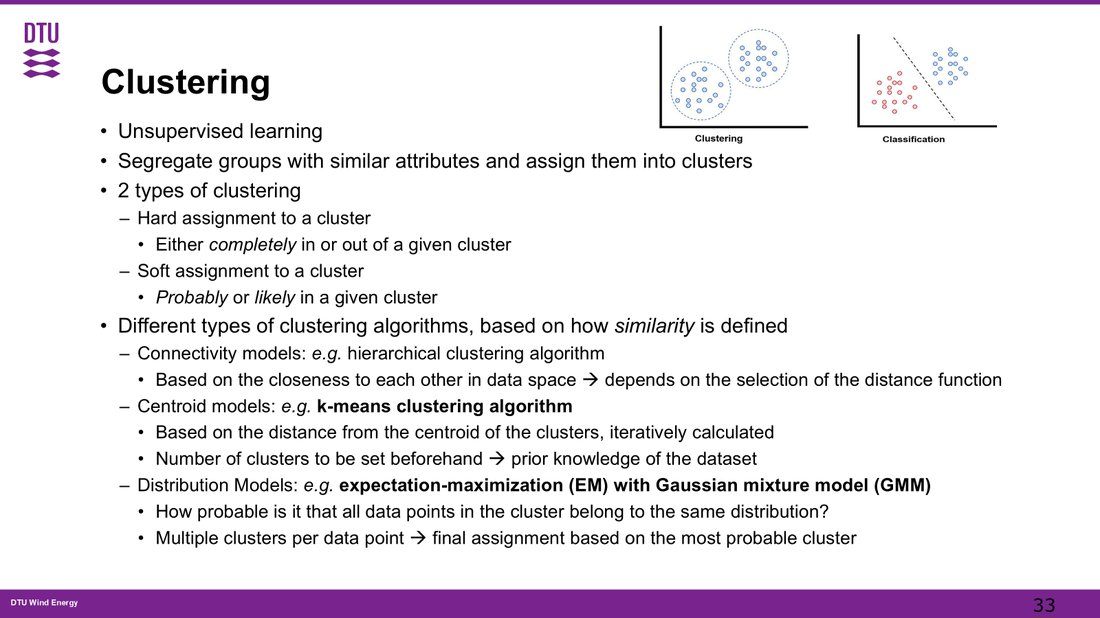

A **GMM** models the data as a mixture of *k* Gaussian "blobs", fitted with the expectation-maximisation (EM) algorithm. Every record receives a **probability** of belonging to each blob (*soft assignment*); `predict` returns the most probable one.

The main parameter is the **number of components** *k*, which we have to choose ourselves. A common tool is the **BIC** (Bayesian information criterion): it rewards a good fit but penalises extra components, so *lower is better*.

### Choosing the number of components

We fit GMMs with 1 to 10 components.

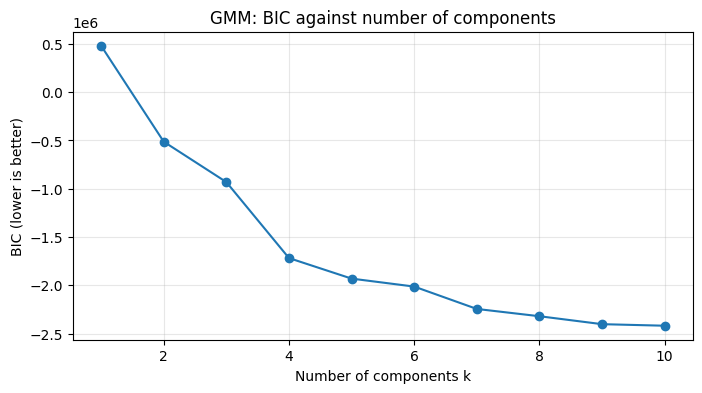

In [20]:
from sklearn.mixture import GaussianMixture

k_range = range(1, 11)
bic = [GaussianMixture(n_components=k, random_state=42).fit(X01_sc).bic(X01_sc) for k in k_range]

plt.figure(figsize=(8, 4))
plt.plot(k_range, bic, 'o-')
plt.xlabel('Number of components k'); plt.ylabel('BIC (lower is better)')
plt.title('GMM: BIC against number of components'); plt.grid(alpha=0.3); plt.show()

The BIC keeps falling as we add components: the data is **not** made of perfectly Gaussian blobs (think of the curved power curve), so additional components mostly carve the existing bands into smaller pieces. We look for the point where the big gains stop and the clusters stay **physically interpretable**. The improvement up to **k = 4** is large, afterwards it is only moderate.

GMM with 4 components fitted in 2.9 s


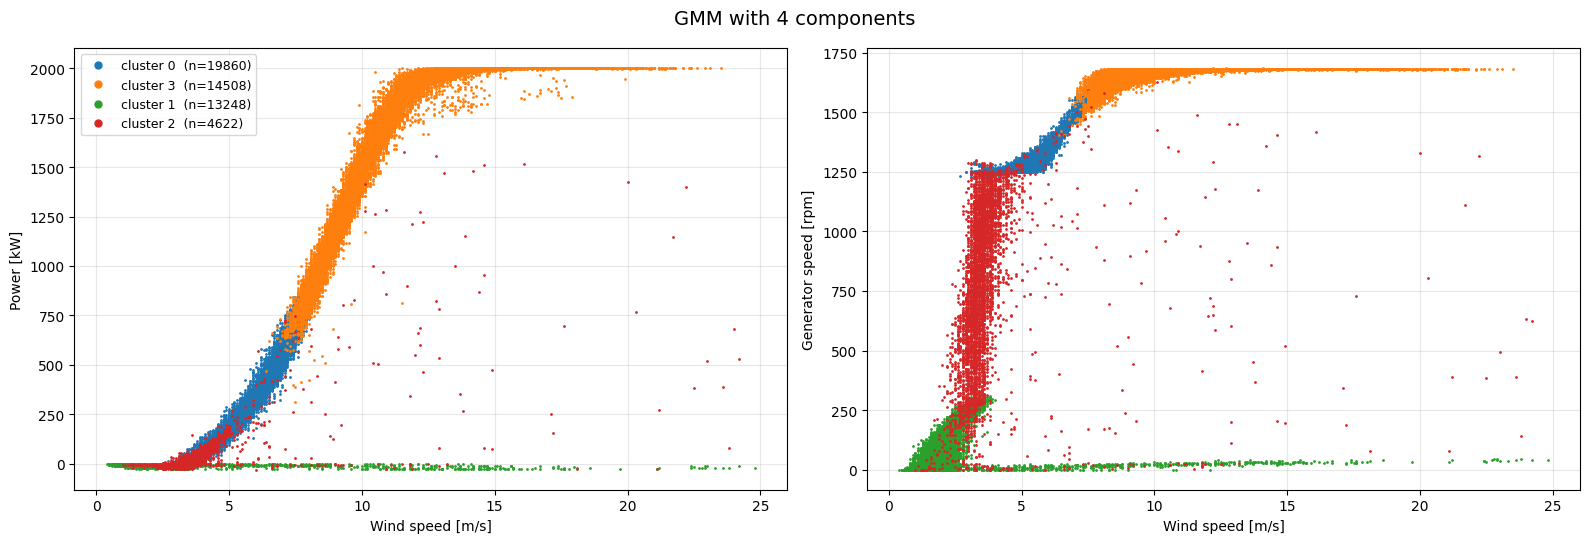

In [26]:
n_components = 4

t0 = time.perf_counter()
GM_model = GaussianMixture(n_components=n_components, random_state=42, n_init=3).fit(X01_sc)
gmm_labels = GM_model.predict(X01_sc)
fit_time['GMM'] = time.perf_counter() - t0
print(f'GMM with {n_components} components fitted in {fit_time["GMM"]:.1f} s')

plot_clusters(gmm_labels, f'GMM with {n_components} components')

### Read and name the clusters

The colours are arbitrary: cluster 0 is *not* "operational" by definition, and the numbering can differ from machine to machine. To understand what each cluster represents we **profile** it: the median of key channels per cluster.

In [25]:
cluster_profile(gmm_labels)

,size,Amb_WindSpeed_Avg,Grd_Prod_Pwr_Avg,Grd_Prod_Pwr_Min,Gen_RPM_Min,Gen_RPM_Max,Blds_PitchAngle_Avg
0,19860,5.6,274.3,98.2,1234.4,1482.8,-1.5
1,13248,2.2,-4.9,-24.3,76.7,159.8,24.0
2,4622,3.4,2.9,-36.6,200.0,1364.3,11.7
3,14508,10.3,1576.9,911.0,1583.3,1725.3,-0.9


**Normal operation** means the generator stayed at operating speed during the *whole* 10 minutes (high `Gen_RPM_Min`) and the turbine kept producing power (`Grd_Prod_Pwr_Min` > 0).

- Which clusters fulfil this?
- What do the other clusters represent? (Think of idling at low wind and start-up ramps: look at `Gen_RPM_Max`, `Blds_PitchAngle_Avg`...)

In [27]:
prof = cluster_profile(gmm_labels)
normal_gmm = prof.index[(prof['Gen_RPM_Min'] >= 1000) & (prof['Grd_Prod_Pwr_Min'] > 0)].tolist()
print('Normal-operation clusters:', normal_gmm)

results['GMM'] = np.isin(gmm_labels, normal_gmm)
pd.DataFrame([evaluate_filter(results['GMM'], 'GMM')])

Normal-operation clusters: [0, 3]


,method,kept [%],precision,recall,F1
0,GMM,65.8,0.896,1.0,0.945


**Soft assignment in practice.** The GMM gives us more than a label: `predict_proba` tells us *how sure* the model is. Where is it unsure?

Records with confidence < 0.9: 380 (0.7%)


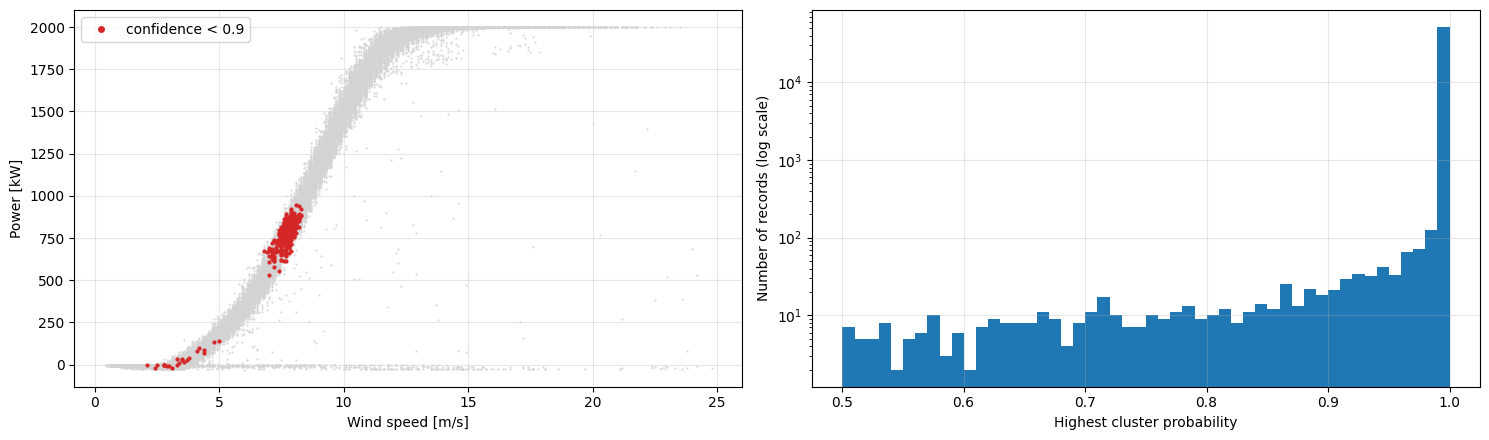

In [28]:
confidence = GM_model.predict_proba(X01_sc).max(axis=1)
unsure = confidence < 0.9
print(f'Records with confidence < 0.9: {unsure.sum()} ({unsure.mean():.1%})')

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(T01['Amb_WindSpeed_Avg'], T01['Grd_Prod_Pwr_Avg'], '.', ms=1, color='lightgrey')
ax[0].plot(T01['Amb_WindSpeed_Avg'][unsure], T01['Grd_Prod_Pwr_Avg'][unsure], '.', ms=4, color='C3', label='confidence < 0.9')
ax[0].set_xlabel('Wind speed [m/s]'); ax[0].set_ylabel('Power [kW]'); ax[0].legend(markerscale=2); ax[0].grid(alpha=0.3)
ax[1].hist(confidence, bins=50, log=True)
ax[1].set_xlabel('Highest cluster probability'); ax[1].set_ylabel('Number of records (log scale)'); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Almost every record is assigned with a probability close to 1: in 16 dimensions the Gaussians are very well separated, so the "soft" assignment is almost hard here. The few unsure records (red) sit in one spot in the **middle of the power curve**, exactly where the GMM cuts the single operational band into two Gaussians: an artefact of the model, not a physical boundary.

Also remember that these probabilities are **relative** to the other components: the GMM cannot say *"this record belongs to none of them"*. DBSCAN and HDBSCAN can: they give such records the label **−1 (noise)**. Let us see what they do.

---
## 5.2 DBSCAN

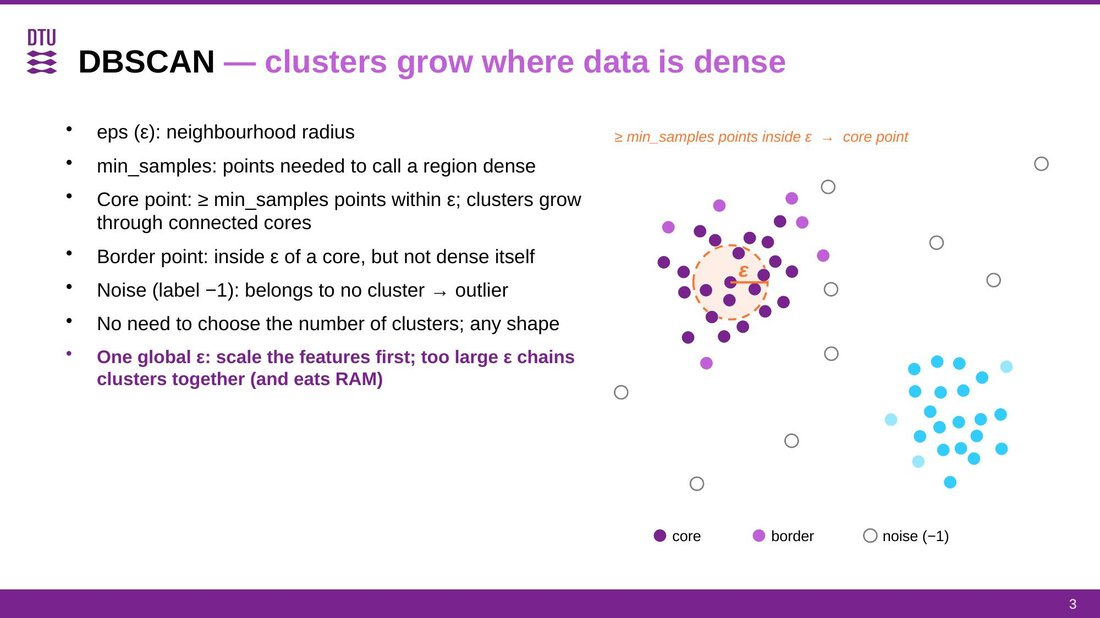

**DBSCAN** (density-based spatial clustering of applications with noise) has two parameters:

- `eps` (ε): the radius of a record's neighbourhood
- `min_samples`: how many records must lie within `eps` for the region to count as dense

Records in dense regions form clusters, which grow through neighbouring dense records; records in sparse regions receive the label **−1 (noise)**. We do not have to choose the number of clusters.

### Choosing `eps` with the k-distance plot

For every record we compute the distance to its `min_samples`-th nearest neighbour and sort these distances. Most records lie in dense regions (small distances); the curve rises steeply for the few records in sparse regions. A good `eps` is near the **start of the upward bend** (the "knee"). Be careful not to pick the *steepest* part of the curve: there `eps` is already so large that clusters start to merge (we will discuss this towards the end also).

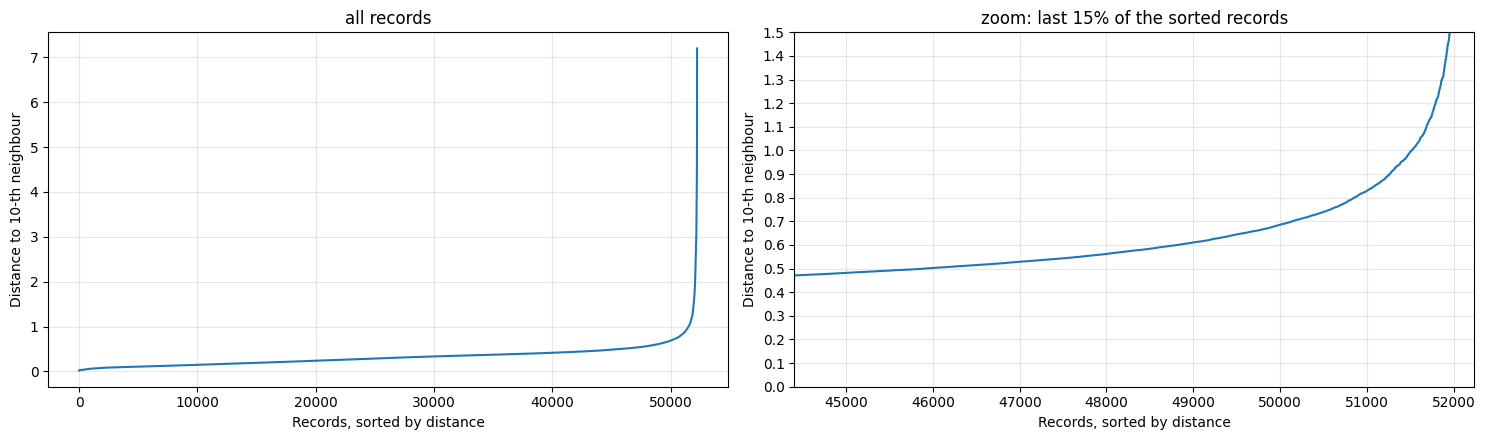

In [29]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

min_samples = 10
nn = NearestNeighbors(n_neighbors=min_samples, algorithm='kd_tree').fit(X01_sc)
distances, _ = nn.kneighbors(X01_sc)
k_dist = np.sort(distances[:, -1])        # distance to the 10th nearest neighbour (the record itself counts as the 1st)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(k_dist); ax[0].set_title('all records')
ax[1].plot(k_dist); ax[1].set_title('zoom: last 15% of the sorted records')
ax[1].set_xlim(0.85 * len(k_dist), len(k_dist)); ax[1].set_ylim(0, 1.5); ax[1].set_yticks(np.arange(0, 1.6, 0.1))
for a in ax:
    a.set_xlabel('Records, sorted by distance'); a.set_ylabel(f'Distance to {min_samples}-th neighbour'); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

We use `min_samples = 10`. (A common rule of thumb is 2 × number of features = 32; a smaller value gives less noise but more small clusters, and our operating states are very dense.)

> **Memory:** DBSCAN stores the neighbourhood of every record. The larger `eps`, the more neighbours, and **RAM use grows quickly**: about 2 GB at the value used here, and several GB for `eps` ≥ 0.8. Do not try large values on a small laptop!

DBSCAN: 10 clusters, 3.5% noise, fitted in 2.0 s


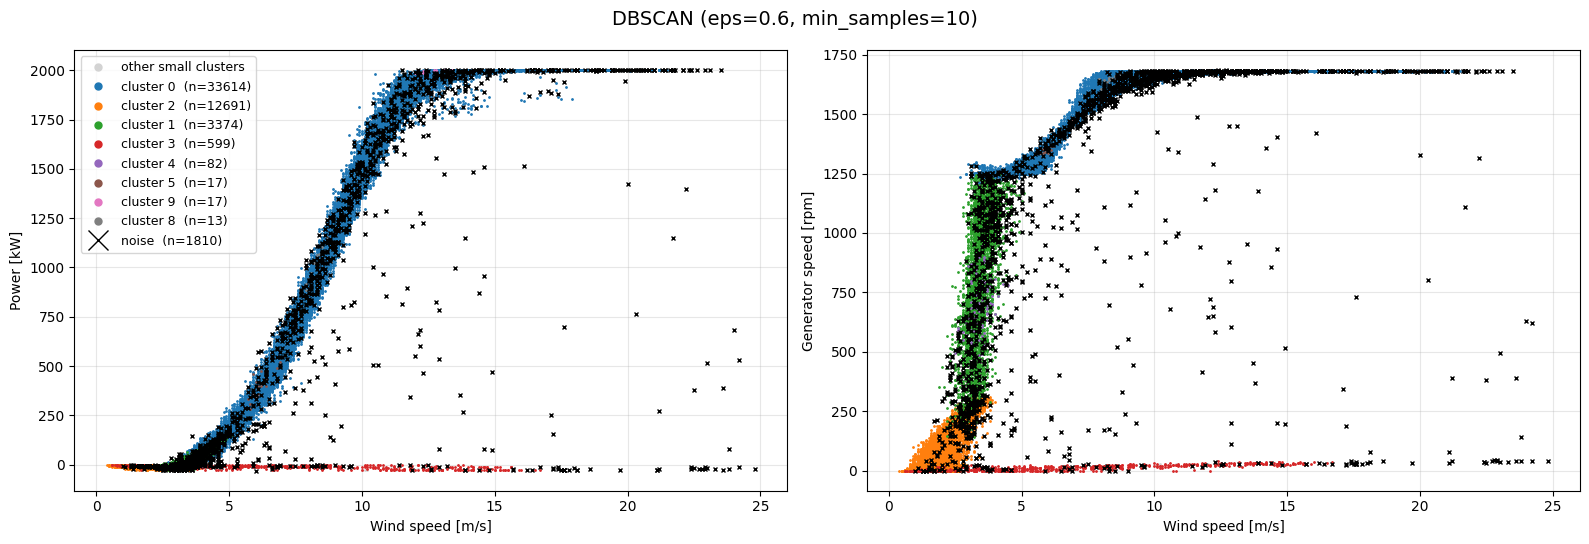

In [30]:
eps = 0.6

t0 = time.perf_counter()
dbscan_model = DBSCAN(eps=eps, min_samples=min_samples).fit(X01_sc)
dbscan_labels = dbscan_model.labels_
fit_time['DBSCAN'] = time.perf_counter() - t0

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
print(f'DBSCAN: {n_clusters} clusters, {np.mean(dbscan_labels == -1):.1%} noise, fitted in {fit_time["DBSCAN"]:.1f} s')

plot_clusters(dbscan_labels, f'DBSCAN (eps={eps}, min_samples={min_samples})')

Profile the clusters again (the row with label **−1** describes the noise records):

In [31]:
cluster_profile(dbscan_labels)

,size,Amb_WindSpeed_Avg,Grd_Prod_Pwr_Avg,Grd_Prod_Pwr_Min,Gen_RPM_Min,Gen_RPM_Max,Blds_PitchAngle_Avg
-1,1810,6.8,195.1,-25.1,265.6,1612.2,7.8
0,33614,7.0,561.8,249.8,1261.3,1662.8,-1.4
1,3374,3.4,2.7,-37.1,220.6,1366.5,10.4
2,12691,2.1,-4.8,-24.3,87.2,170.9,24.0
3,599,6.3,-7.9,-27.0,0.0,41.6,86.0
4,82,3.4,1.1,-41.8,0.0,1276.8,35.0
5,17,6.1,400.7,101.6,1229.0,1616.6,-1.7
6,12,11.0,-24.3,-42.8,0.0,77.6,86.0
7,9,5.4,240.5,48.5,1225.4,1432.5,-1.4
8,13,8.3,1024.6,428.5,1427.5,1717.9,-2.2


DBSCAN found a few big clusters and several tiny ones, plus a few percent of noise. Compare the profile with the GMM: the same operating states appear (normal operation, idling at low wind, start-up transients), but DBSCAN may also find a *parked* state (generator speed 0) that the GMM merged with idling, and it flags the sparse edges of the bands as noise.

Select the normal-operation clusters in the same way as before, and remember to exclude the **noise (−1)**.

In [32]:
prof = cluster_profile(dbscan_labels)
normal_dbscan = prof.index[(prof.index >= 0) & (prof['Gen_RPM_Min'] >= 1000) & (prof['Grd_Prod_Pwr_Min'] > 0)].tolist()
print('Normal-operation clusters:', normal_dbscan)

results['DBSCAN'] = np.isin(dbscan_labels, normal_dbscan)
pd.DataFrame([evaluate_filter(results['DBSCAN'], 'DBSCAN')])

Normal-operation clusters: [0, 5, 7, 8, 9]


,method,kept [%],precision,recall,F1
0,DBSCAN,64.5,0.892,0.975,0.931


### How to read the evaluation table

**Precision:** “How clean is what we kept?” It drops e.g., when we keep records the reference calls start-up or idling. Precision is measured against the **reference or rule**, not against physical truth. A precision of ≈ 0.89 does not necessarily mean 11% of the records are mistakes

**Recall:** “How much of the good data did we keep?” It drops when we throw away operational records, for example as DBSCAN noise or by leaving a cluster out of normal_dbscan.

**F1** one number combining both: 2·P·R / (P + R), high only if precision *and* recall are high. If one is poor, it falls sharply, which is why it is a better summary than the average of the two.



## 5.3 HDBSCAN

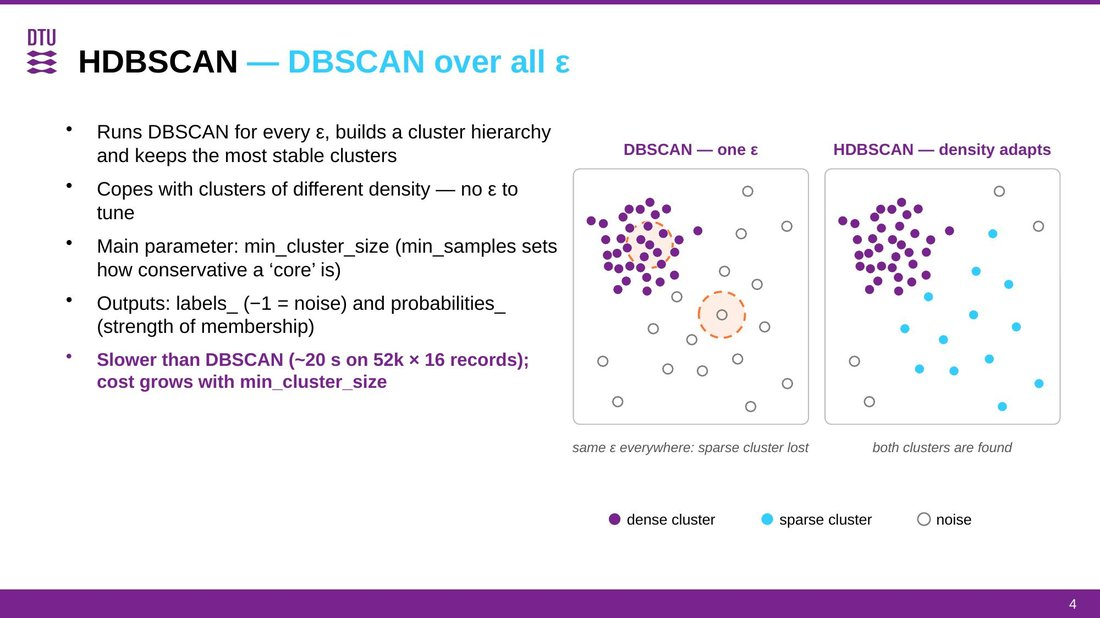

**HDBSCAN** (hierarchical DBSCAN) removes the need to choose `eps`: it runs DBSCAN for *all* values of `eps`, builds a hierarchy of clusters and keeps the clusters that are the most **stable**. This lets it find clusters of **different density** in the same data set.

The main parameter is `min_cluster_size`: the smallest group of records we are willing to call a cluster. Its outputs are the labels (`labels_`, −1 = noise) and `probabilities_`, the strength with which a record belongs to its cluster.

> **Speed:** HDBSCAN is slower than DBSCAN, because it builds the whole cluster hierarchy. Time and memory grow with `min_cluster_size`.

HDBSCAN: 4 clusters, 3.8% noise, fitted in 31.3 s


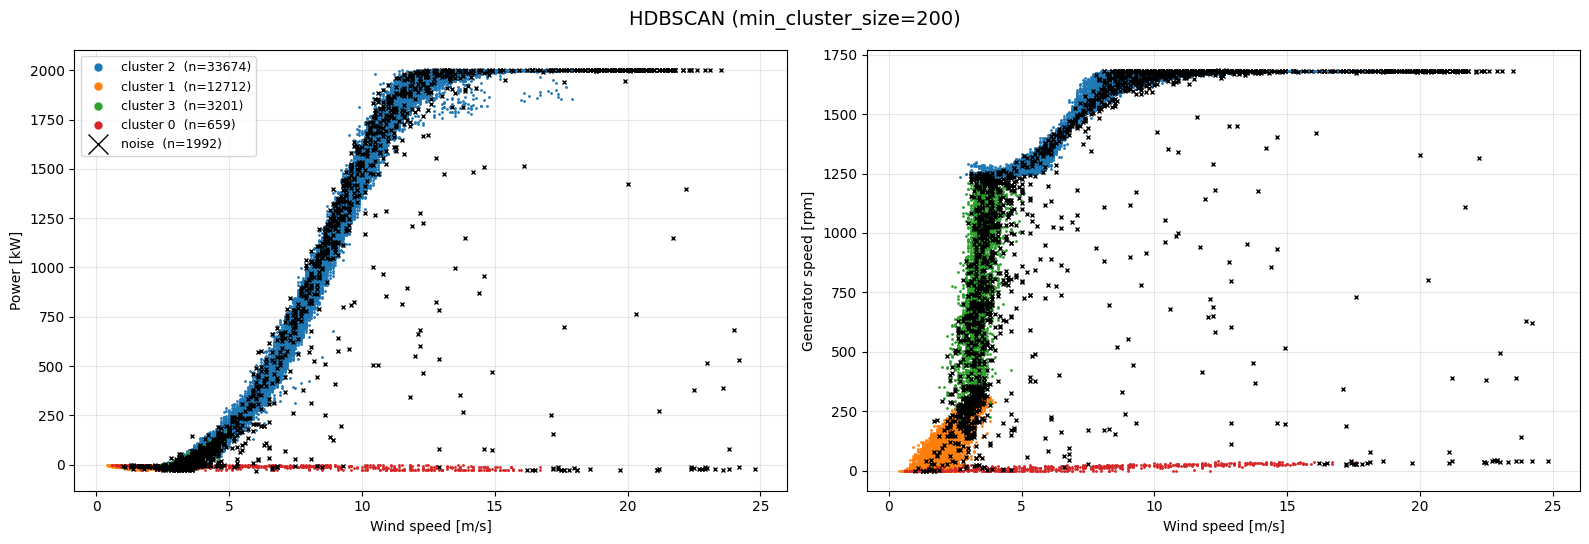

In [33]:
from sklearn.cluster import HDBSCAN

min_cluster_size = 200 # feel free to experiment with different sizes here 

t0 = time.perf_counter()
hdbscan_model = HDBSCAN(min_cluster_size=min_cluster_size, copy=True).fit(X01_sc)
hdbscan_labels = hdbscan_model.labels_
fit_time['HDBSCAN'] = time.perf_counter() - t0

n_clusters = len(set(hdbscan_labels)) - (1 if -1 in hdbscan_labels else 0)
print(f'HDBSCAN: {n_clusters} clusters, {np.mean(hdbscan_labels == -1):.1%} noise, fitted in {fit_time["HDBSCAN"]:.1f} s')

plot_clusters(hdbscan_labels, f'HDBSCAN (min_cluster_size={min_cluster_size})')

HDBSCAN needs only one parameter and finds a handful of clearly separated, interpretable clusters. Profile them:

In [34]:
cluster_profile(hdbscan_labels)

,size,Amb_WindSpeed_Avg,Grd_Prod_Pwr_Avg,Grd_Prod_Pwr_Min,Gen_RPM_Min,Gen_RPM_Max,Blds_PitchAngle_Avg
-1,1992,5.2,101.7,-26.7,265.4,1476.8,10.0
0,659,6.7,-7.9,-27.0,0.0,44.3,86.0
1,12712,2.1,-4.8,-24.3,87.4,171.2,24.0
2,33674,7.0,561.2,248.4,1260.8,1662.8,-1.4
3,3201,3.4,3.0,-37.6,217.6,1367.7,10.4


Each cluster now has a clear physical meaning: normal operation (generator at ~1260 rpm or more, positive power), idling (blades feathered, generator almost stopped), a *parked* state with the blades turned out at ~90°, and start-up transients. Select the normal-operation clusters:

In [35]:
prof = cluster_profile(hdbscan_labels)
normal_hdbscan = prof.index[(prof.index >= 0) & (prof['Gen_RPM_Min'] >= 1000) & (prof['Grd_Prod_Pwr_Min'] > 0)].tolist()
print('Normal-operation clusters:', normal_hdbscan)

results['HDBSCAN'] = np.isin(hdbscan_labels, normal_hdbscan)
pd.DataFrame([evaluate_filter(results['HDBSCAN'], 'HDBSCAN')])

Normal-operation clusters: [2]


,method,kept [%],precision,recall,F1
0,HDBSCAN,64.5,0.891,0.974,0.931


### How to read the evaluation table

**Precision:** “How clean is what we kept?” It drops e.g., when we keep records the reference calls start-up or idling. Precision is measured against the **reference or rule**, not against physical truth. A precision of ≈ 0.89 does not necessarily mean 11% of the records are mistakes

**Recall:** “How much of the good data did we keep?” It drops when we throw away operational records, for example as DBSCAN noise or by leaving a cluster out of normal_dbscan.

**F1** one number combining both: 2·P·R / (P + R), high only if precision *and* recall are high. If one is poor, it falls sharply, which is why it is a better summary than the average of the two.


HDBSCAN also returns `probabilities_`, the **strength of membership** of every record in its cluster (0 for noise). Let us look at the clusters' members:

,meaning,records,median strength,weak (< 0.3) [%],strong (> 0.8) [%]
cluster,,,,,
0,parked (blades turned out),659,0.86,0,60
1,idling,12712,0.62,4,13
2,normal operation,33674,0.39,20,5
3,start-up / transient,3201,0.63,0,19


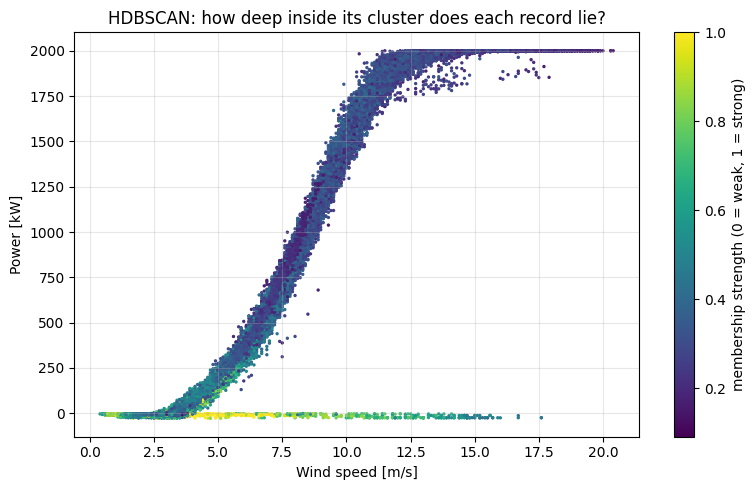

In [36]:
prob = hdbscan_model.probabilities_
members = hdbscan_labels >= 0
prof = cluster_profile(hdbscan_labels)

def name_cluster(c, row):
    """Name a cluster from its profile (the cluster numbering is arbitrary, the physics is not)."""
    if c == -1:
        return 'noise'
    if row['Gen_RPM_Min'] >= 1000 and row['Grd_Prod_Pwr_Min'] > 0:
        return 'normal operation'
    if row['Gen_RPM_Max'] < 500:
        return 'parked (blades turned out)' if row['Blds_PitchAngle_Avg'] > 60 else 'idling'
    return 'start-up / transient'

rows = []
for c in prof.index[prof.index >= 0]:
    p = prob[hdbscan_labels == c]
    rows.append({'cluster': c, 'meaning': name_cluster(c, prof.loc[c]), 'records': len(p),
                 'median strength': round(np.median(p), 2),
                 'weak (< 0.3) [%]': round(100 * np.mean(p < 0.3)),
                 'strong (> 0.8) [%]': round(100 * np.mean(p > 0.8))})
display(pd.DataFrame(rows).set_index('cluster'))

fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(T01['Amb_WindSpeed_Avg'][members], T01['Grd_Prod_Pwr_Avg'][members], c=prob[members], s=2, cmap='viridis')
plt.colorbar(sc, label='membership strength (0 = weak, 1 = strong)')
ax.set_xlabel('Wind speed [m/s]'); ax.set_ylabel('Power [kW]'); ax.grid(alpha=0.3)
ax.set_title('HDBSCAN: how deep inside its cluster does each record lie?')
plt.tight_layout(); plt.show()

The membership strengths are spread widely (the median is only around 0.5), so a threshold like "keep probability > 0.8" would throw away most of the normal operation. These scores describe how *deep inside* a cluster a record lies, not how *certain* the assignment is, so they must be interpreted with care. We do **not** filter on them here.

---
# 6 · Comparing and combining the three filters

In [37]:
labels_all = {'GMM': gmm_labels, 'DBSCAN': dbscan_labels, 'HDBSCAN': hdbscan_labels}

summary = pd.DataFrame([evaluate_filter(results[m], m) for m in labels_all])
summary.insert(1, 'clusters', [len(set(l)) - (1 if -1 in l else 0) for l in labels_all.values()])
summary.insert(2, 'noise [%]', [round(100 * np.mean(l == -1), 1) for l in labels_all.values()])
summary['fit time [s]'] = [round(fit_time[m], 1) for m in labels_all]
summary.set_index('method')

,clusters,noise [%],kept [%],precision,recall,F1,fit time [s]
method,,,,,,,
GMM,4,0.0,65.8,0.896,1.000,0.945,2.9
DBSCAN,10,3.5,64.5,0.892,0.975,0.931,2.0
HDBSCAN,4,3.8,64.5,0.891,0.974,0.931,31.3


All three methods keep ~65% of the records and all of them recover (almost) every rule-based operational record (**recall** ≈ 0.97 to 1), with a **precision** of about 0.89. They differ in the number of clusters, in noise handling and in speed.

Where do they remove records? Grey = removed, green = kept (the rule-based reference is shown for comparison):

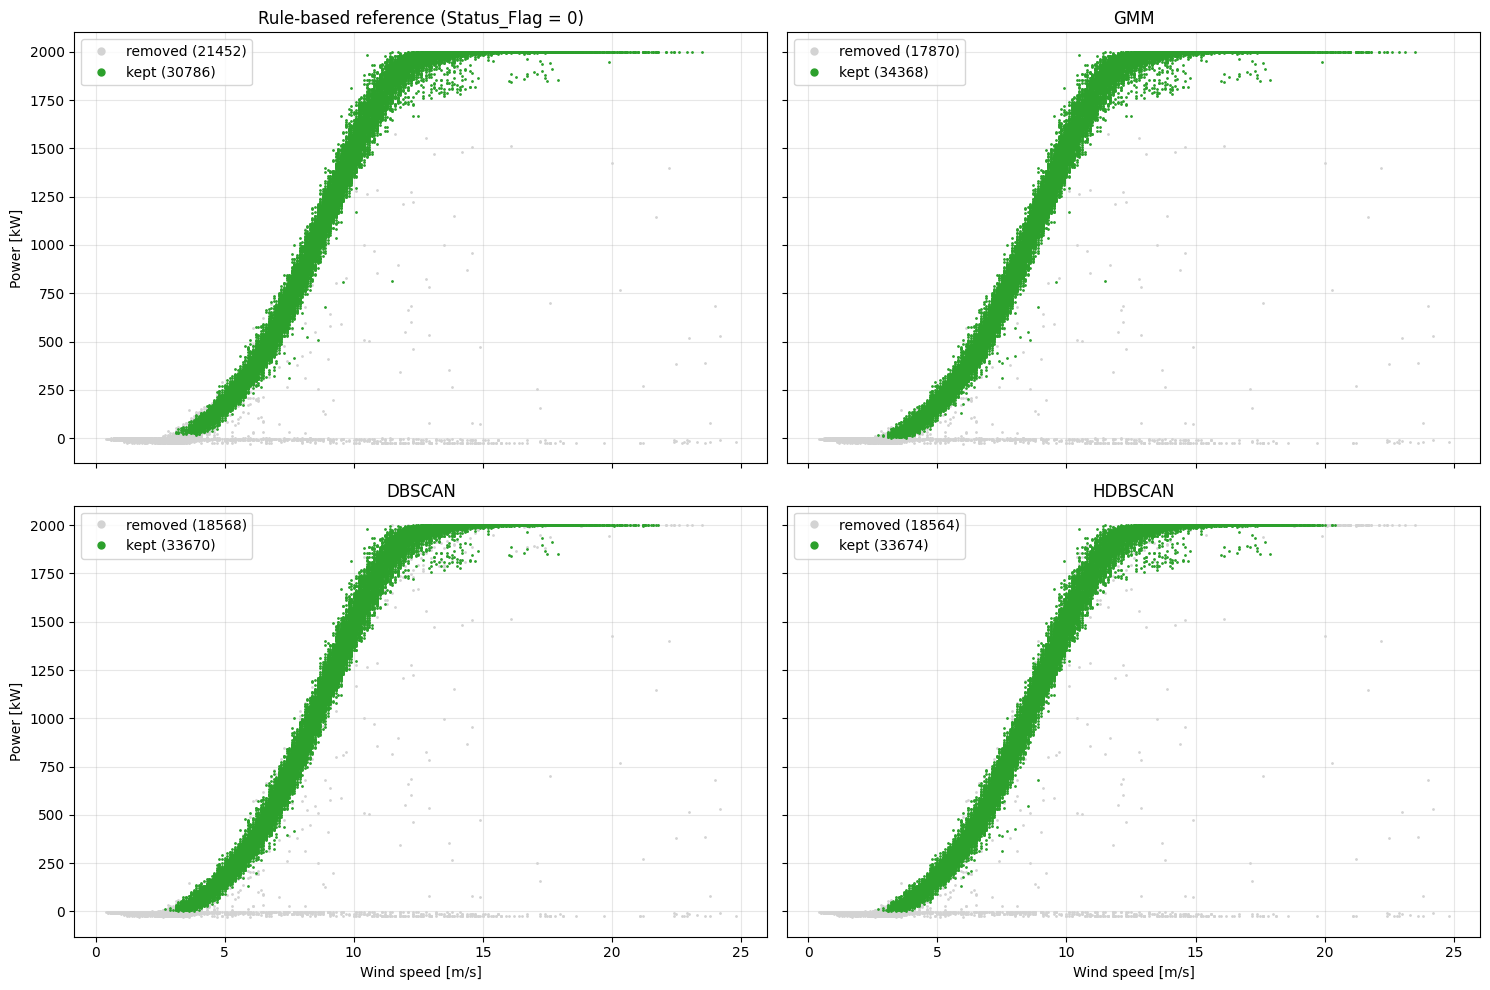

In [38]:
panels = [('Rule-based reference (Status_Flag = 0)', reference), ('GMM', results['GMM'].values),
          ('DBSCAN', results['DBSCAN'].values), ('HDBSCAN', results['HDBSCAN'].values)]

fig, ax = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=True)
for a, (name, keep) in zip(ax.ravel(), panels):
    a.plot(T01['Amb_WindSpeed_Avg'][~keep], T01['Grd_Prod_Pwr_Avg'][~keep], '.', ms=2, color='lightgrey', label=f'removed ({(~keep).sum()})')
    a.plot(T01['Amb_WindSpeed_Avg'][keep], T01['Grd_Prod_Pwr_Avg'][keep], '.', ms=2, color='C2', label=f'kept ({keep.sum()})')
    a.set_title(name); a.grid(alpha=0.3); a.legend(markerscale=5, loc='upper left')
for a in ax[1, :]: a.set_xlabel('Wind speed [m/s]')
for a in ax[:, 0]: a.set_ylabel('Power [kW]')
plt.tight_layout(); plt.show()

At this scale the four panels lookvery similar, and that is the first result: all three methods recover the same band as the rule-based reference. The differences are in the details. 

Let us measure them: which records does *only one side* keep, and what do the noise records of DBSCAN and HDBSCAN look like?

In [39]:
only_gmm     = (results['GMM'] & ~results['DBSCAN'] & ~results['HDBSCAN']).values
only_density = (~results['GMM'] & results['DBSCAN'] & results['HDBSCAN']).values
noise_both   = (dbscan_labels == -1) & (hdbscan_labels == -1)

def describe(mask, name):
    t = T01[mask]
    return {'group': name, 'records': int(mask.sum()),
            'median wind [m/s]': round(t['Amb_WindSpeed_Avg'].median(), 1),
            'median power [kW]': round(t['Grd_Prod_Pwr_Avg'].median(), 0),
            'rule-operational [%]': round(100 * reference[mask].mean(), 0)}

pd.DataFrame([describe(only_gmm, 'kept by GMM only'),
              describe(only_density, 'kept by DBSCAN and HDBSCAN, not by GMM'),
              describe(noise_both, 'noise in both DBSCAN and HDBSCAN')]).set_index('group')

,records,median wind [m/s],median power [kW],rule-operational [%]
group,,,,
kept by GMM only,530,10.5,1616.0,93.0
"kept by DBSCAN and HDBSCAN, not by GMM",113,3.8,46.0,0.0
noise in both DBSCAN and HDBSCAN,1316,5.9,131.0,38.0


Read the table:

- **Kept by GMM only:** records at the upper end of the band (around 10 m/s, high power), and more than 90% of them are operational according to our reference. The density methods call them noise because the band is thin there, so they lose a little recall that the GMM keeps.
- **Kept by DBSCAN and HDBSCAN but not by GMM:** a small group of start-up records (~4 m/s, a few tens of kW), none of them are normal operation. Here the GMM might be right.
- **Noise in both density methods:** about a thousand records, of which 40% are  normal operation. The noise label mostly **trims the weak membership** to the clusters and the transitions; it is not a list of obvious errors.

What about the **isolated points far to the right of the power curve** (a lot of wind, but only partial power)? We select the ones above 15 m/s and ask what each method did with them:

In [40]:
stray = ((T01['Amb_WindSpeed_Avg'] > 15) & T01['Grd_Prod_Pwr_Avg'].between(100, 1500)).values
print(f'{stray.sum()} isolated records far right of the power curve (wind > 15 m/s, power between 100 and 1500 kW)')
print('  kept by the rule-based reference:', reference[stray].sum())
for m in ['GMM', 'DBSCAN', 'HDBSCAN']:
    print(f'  kept by {m:8s}              :', results[m].values[stray].sum())
print('  labelled noise by DBSCAN / HDBSCAN:', (dbscan_labels[stray] == -1).sum(), '/', (hdbscan_labels[stray] == -1).sum())
T01.loc[stray, ['Gen_RPM_Min', 'Grd_Prod_Pwr_Min']].median().round(0).to_frame('median').T

13 isolated records far right of the power curve (wind > 15 m/s, power between 100 and 1500 kW)
  kept by the rule-based reference: 0
  kept by GMM                   : 0
  kept by DBSCAN                : 0
  kept by HDBSCAN               : 0
  labelled noise by DBSCAN / HDBSCAN: 13 / 13


,Gen_RPM_Min,Grd_Prod_Pwr_Min
median,0.0,-44.0


These are **not** erroneous measurements: the generator minimum is ~0 rpm and the minimum power is negative, so the turbine **stopped or started during the 10 minutes**. The *average* power of such a window lies between zero and rated power although the wind blows. The rule and all three methods remove them: DBSCAN and HDBSCAN label them noise, and the GMM puts them into its start-up/transient cluster.

## Combining the methods: a majority vote

Each method makes slightly different mistakes. A simple and robust way to combine them is a **majority vote**: keep a record if *at least 2 of the 3* methods consider it normal operation.

In [41]:
votes = results[['GMM', 'DBSCAN', 'HDBSCAN']].sum(axis=1)     # how many of the 3 methods call each record "normal operation"?

meaning = {1: 'only one says normal', 2: 'two say normal', 3: 'all three say normal'}
vote_table = votes.value_counts().reindex([1, 2, 3], fill_value=0).to_frame('records')
vote_table['share [%]'] = (100 * vote_table['records'] / len(votes)).round(1)
vote_table['rule-operational [%]'] = [round(100 * reference[(votes == v).values].mean()) if (votes == v).any() else None
                                      for v in vote_table.index]
vote_table.index = vote_table.index.map(meaning)      # use the meaning as the row label ...
vote_table.index.name = None                          # ... without an index name
display(vote_table)

results['Consensus'] = votes >= 2          # majority vote: at least 2 of the 3 methods
pd.DataFrame([evaluate_filter(results[m], m) for m in ['GMM', 'DBSCAN', 'HDBSCAN', 'Consensus']]).set_index('method')

,records,share [%],rule-operational [%]
only one says normal,561,1.1,88
two say normal,702,1.3,81
all three say normal,33249,63.6,89


,kept [%],precision,recall,F1
method,,,,
GMM,65.8,0.896,1.000,0.945
DBSCAN,64.5,0.892,0.975,0.931
HDBSCAN,64.5,0.891,0.974,0.931
Consensus,65.0,0.892,0.984,0.936


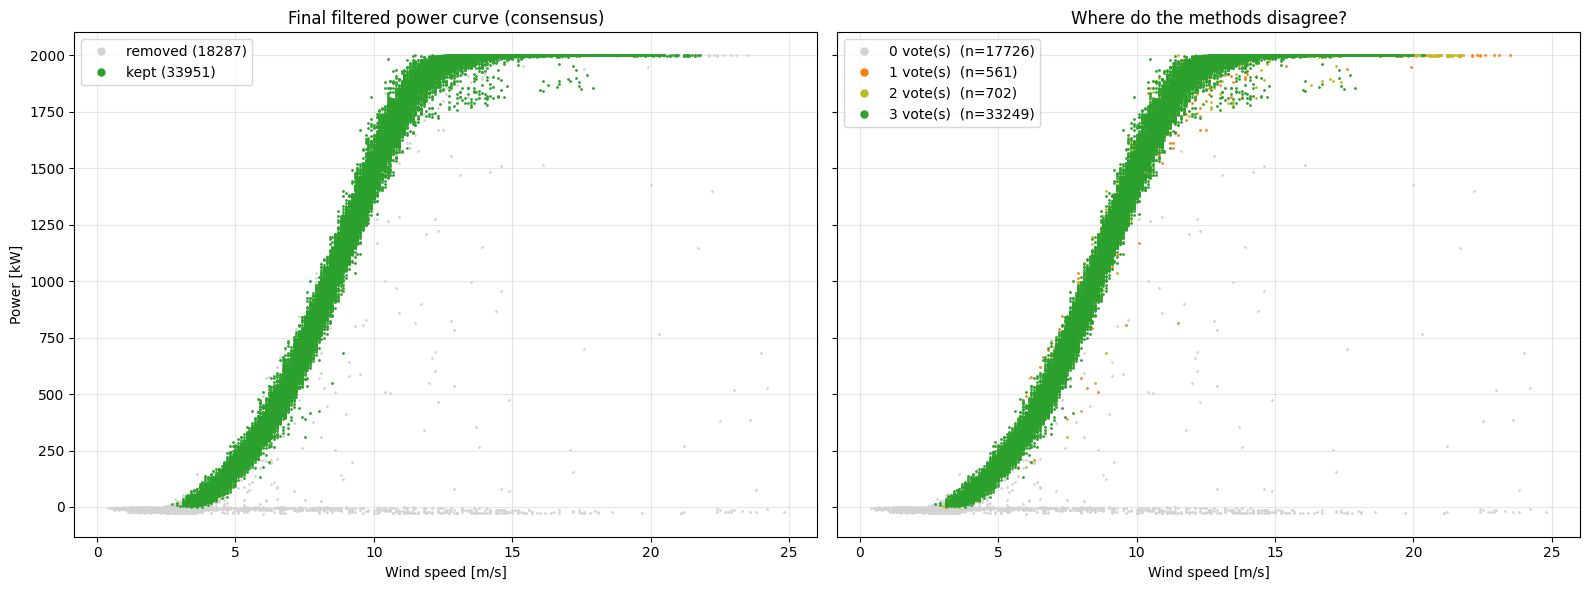

In [42]:
keep = results['Consensus'].values
vote_colors = {0: 'lightgrey', 1: 'C1', 2: 'C8', 3: 'C2'}

fig, ax = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
ax[0].plot(T01['Amb_WindSpeed_Avg'][~keep], T01['Grd_Prod_Pwr_Avg'][~keep], '.', ms=2, color='lightgrey', label=f'removed ({(~keep).sum()})')
ax[0].plot(T01['Amb_WindSpeed_Avg'][keep], T01['Grd_Prod_Pwr_Avg'][keep], '.', ms=2, color='C2', label=f'kept ({keep.sum()})')
ax[0].set_title('Final filtered power curve (consensus)')
for v in (0, 1, 2, 3):
    m = (votes == v).values
    ax[1].plot(T01['Amb_WindSpeed_Avg'][m], T01['Grd_Prod_Pwr_Avg'][m], '.', ms=2, color=vote_colors[v], label=f'{v} vote(s)  (n={m.sum()})')
ax[1].set_title('Where do the methods disagree?')
for a in ax: a.set_xlabel('Wind speed [m/s]'); a.grid(alpha=0.3); a.legend(markerscale=5, loc='upper left')
ax[0].set_ylabel('Power [kW]')
plt.tight_layout(); plt.show()

The methods disagree mostly at the **edges** of the operational band, where the density thins out and "normal" gradually turns into "start-up" or "unusual". The consensus filter gives a clean power curve for the most part, which is what is needed for normal behaviour modelling, for example.

---
# 7 · Extra experiments (if we  have time)

## 7.1 Why do we need the Min / Max / Std features?

What if we cluster only on the four **average** values (wind speed, power, generator speed, pitch angle)? Let us run DBSCAN on those alone.

In [43]:
avg_features = [f for f in FeatureNames if f.endswith('_Avg')]
X_avg = StandardScaler().fit_transform(T01[avg_features])

dbscan_avg = DBSCAN(eps=0.1, min_samples=10).fit_predict(X_avg)
sizes = pd.Series(dbscan_avg[dbscan_avg >= 0]).value_counts()
print(f'{len(sizes)} clusters; the largest one holds {sizes.iloc[0] / len(X_avg):.0%} of all records; noise: {np.mean(dbscan_avg == -1):.1%}')

keep_avg = dbscan_avg == sizes.index[0]
display(pd.DataFrame([evaluate_filter(keep_avg, 'DBSCAN, 4 Avg features only')]).set_index('method'))

8 clusters; the largest one holds 98% of all records; noise: 1.2%


,kept [%],precision,recall,F1
method,,,,
"DBSCAN, 4 Avg features only",97.6,0.603,0.999,0.752


With the averages alone, the operating states are not separable: start-up ramps and idling blend continuously into the power curve, so DBSCAN **chains** almost everything into one huge cluster. Keeping that cluster is hardly better than keeping *everything* (precision ≈ 0.60, against 0.59, the share of operational records, if we kept all records). The Min/Max/Std features carry the information on what happened *inside* the 10 minutes, and that is what lets the algorithms separate the states.

## 7.2 What happens if `eps` is too large? (try at home)

At `eps` = 0.6 the operational band, the idling states and the start-up ramps are separate clusters. But `eps` has a *cliff*: slightly larger, and the clusters chain together.

> This needs **~3 GB of free RAM** and takes a few seconds. Set `run_big_eps = True` only if your computer can afford it.

In [44]:
run_big_eps = True

if run_big_eps:
    big = DBSCAN(eps=0.75, min_samples=min_samples).fit_predict(X01_sc)
    sizes = pd.Series(big[big >= 0]).value_counts()
    print(f'eps = 0.75: {len(sizes)} clusters; the largest holds {sizes.iloc[0] / len(big):.0%} of all records')
    display(pd.DataFrame([evaluate_filter(big == sizes.index[0], 'DBSCAN eps = 0.75, largest cluster')]).set_index('method'))

eps = 0.75: 7 clusters; the largest holds 96% of all records


,kept [%],precision,recall,F1
method,,,,
"DBSCAN eps = 0.75, largest cluster",96.5,0.602,0.986,0.748


Beyond `eps` ≈ 0.7 the start-up ramps and idling states get connected to the operational band, one giant cluster appears, and precision drops to about 0.6. This is the "chaining" problem of density-based clustering with **one global `eps`**.

